### The primary goal is to predict house prices based on various features of the properties such as the size, location and condition

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [ ]:
predictor = pd.read_csv("/content/drive/MyDrive/House Prices Predictor/AmesHousing.csv")

In [ ]:
predictor.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [ ]:
predictor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [ ]:
predictor.isnull().sum()

,0
Order,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,490
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [ ]:
predictor.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [ ]:
numerical_cols = predictor.select_dtypes(include='object')
display(numerical_cols.describe())

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2930,2930,198,2930,2930,2930,2930,2930,2930,2930,...,2773,2771,2771,2771,2930,13,572,106,2930,2930
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,5,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Ex,MnPrv,Shed,WD,Normal
freq,2273,2918,120,1859,2633,2927,2140,2789,443,2522,...,1731,1231,2615,2665,2652,4,330,95,2536,2413


### Insights from Numerical Data

Based on the descriptive statistics for numerical columns, here are some initial insights:

*   **`Order` and `PID`**: These are unique identifiers and do not carry predictive power for house prices. 'Order' ranges from 1 to 2930, indicating 2930 observations in the dataset. 'PID' (Property ID) also represents unique properties.
*   **`MS SubClass`**: This indicates the type of dwelling. Its mean is around 57, with a wide standard deviation, suggesting a variety of dwelling types.
*   **`Lot Frontage`**: The average lot frontage is about 69 feet, but there's a significant number of missing values (count 2440 out of 2930), which will need to be addressed during data cleaning.
*   **`Lot Area`**: The average lot size is around 10,147 sq ft, but the max value (215,245 sq ft) indicates the presence of some very large outliers. The standard deviation is also quite large (7,880 sq ft), suggesting a wide range of lot sizes.
*   **`Overall Qual` and `Overall Cond`**: These are important features indicating the overall quality and condition of the house. They range from 1 to 10 and 1 to 9 respectively, with means around 6 and 5.5, suggesting most houses are of average to good quality/condition.
*   **`Year Built` and `Year Remod/Add`**: These provide information about the age of the house. Houses were built between 1872 and 2010, with an average build year of 1971. The `Year Remod/Add` indicates if and when a house was remodeled.
*   **`Mas Vnr Area`**: The mean masonry veneer area is about 101 sq ft, but there's a high count of zeros (min=0) and a high standard deviation, suggesting many houses might not have masonry veneer, while others have significant areas. There are also some missing values.
*   **`SalePrice`**: This is our target variable. The average sale price is approximately $180,796, with a considerable standard deviation of $79,886. Prices range from a minimum of $12,789 to a maximum of $755,000, indicating a wide distribution and potential for outliers.
*   **Other numerical features**: Features like various 'SF' (square feet) columns (e.g., `1st Flr SF`, `2nd Flr SF`, `Total Bsmt SF`), `Garage Area`, and `Wood Deck SF` give insights into the size and amenities of the properties. Many of these have min values of 0, indicating absence of such features for some properties.

### Statistics for Categorical Data

In [ ]:
categorical_cols = predictor.select_dtypes(include='object')
display(categorical_cols.describe())

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2930,2930,198,2930,2930,2930,2930,2930,2930,2930,...,2773,2771,2771,2771,2930,13,572,106,2930,2930
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,5,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Ex,MnPrv,Shed,WD,Normal
freq,2273,2918,120,1859,2633,2927,2140,2789,443,2522,...,1731,1231,2615,2665,2652,4,330,95,2536,2413


### Insights from Categorical Data

Based on the descriptive statistics for categorical columns, here are some initial insights:

*   **`MS Zoning`**: This describes the general zoning classification. 'RL' (Residential Low Density) is by far the most common zoning, accounting for 2273 out of 2930 properties, indicating a prevalence of single-family homes in residential areas.
*   **`Street`**: All but 12 properties have 'Pave' (Paved) street access, suggesting that 'Grvl' (Gravel) is a rare occurrence and might not be a strong differentiating factor.
*   **`Alley`**: A significant majority of properties (2930 - 198 = 2732) have no alley access (NaN), suggesting that having an alley might be a unique feature.
*   **`Lot Shape`**: 'Reg' (Regular) lot shape is the most frequent, making up 1859 properties. This implies that irregularly shaped lots (`IR1`, `IR2`, `IR3`) are less common.
*   **`Land Contour`**: Most properties (`Lvl`, Level) have a level land contour, which is typical.
*   **`Utilities`**: Almost all properties have 'AllPub' (All public utilities), with very few exceptions. This feature likely has minimal predictive value due to its lack of variation.
*   **`Neighborhood`**: There are 28 unique neighborhoods, with 'NAmes' (North Ames) being the most frequent. Neighborhood is often a crucial factor in house prices, so this will be an important feature.
*   **`Bldg Type` and `House Style`**: These features describe the type of dwelling and its style (e.g., '1Fam' for single-family, '1Story' for one-story). They indicate the structural characteristics of the houses.
*   **`Exterior 1st` and `Exterior 2nd`**: These describe the exterior covering of the house. The presence of two such columns suggests that some houses might have different materials on different parts of their exterior.
*   **`Bsmt Qual`, `Bsmt Cond`, `Bsmt Exposure`, `BsmtFin Type 1`, `BsmtFin Type 2`**: These features describe various aspects of the basement. The large number of `NaN` values for many of these columns (e.g., `Bsmt Qual` has 2850 non-null values out of 2930) indicates that many properties might not have a basement, or the `NaN` values signify 'no basement'.
*   **`Garage Type`, `Garage Finish`, `Garage Qual`, `Garage Cond`**: Similar to basement features, `NaN` values in these columns (e.g., `Garage Type` has 2773 non-null values out of 2930) likely indicate properties without a garage.
*   **`Pool QC`**: With only 13 non-null values out of 2930, this feature indicates that very few properties have pools, making it a highly sparse feature.
*   **`Fence` and `Misc Feature`**: These also have a high number of missing values, suggesting they are not common features across all properties. 'MnPrv' (Minimum Privacy) is the most common fence type, and 'Shed' is the most common miscellaneous feature.
*   **`Sale Type` and `Sale Condition`**: These describe the nature of the sale (e.g., 'WD' for Warranty Deed, 'Normal' for Normal Sale). These could potentially influence sale price.

### Visualizing Missing Values

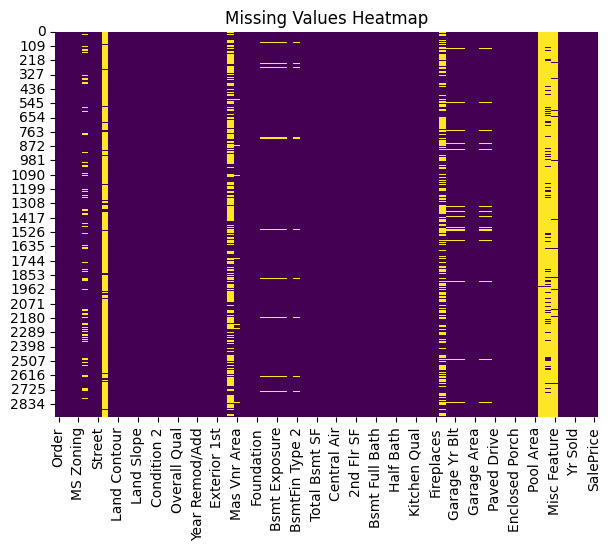

In [ ]:
plt.figure(figsize = (7, 5))
sns.heatmap(predictor.isnull(), cbar = False, cmap = 'viridis')
plt.title("Missing Values Heatmap")
plt.show()

### Missing Values Heatmap Insights

Based on the heatmap generated, here's a breakdown of the insights:

1.  **Colors Represent Missingness**:
    *   The heatmap uses a `viridis` colormap. In this scheme, darker colors (purple/dark blue) indicate the presence of data (non-missing values), while brighter colors (yellow/light green) represent missing values (NaNs). This immediately draws attention to the columns and rows with missing information.

2.  **Identifying Columns with Missing Data**:
    *   Visually, any column that contains vertical yellow streaks across its length has missing data. The prominent yellow streaks clearly highlight columns like 'Lot Frontage', 'Alley', 'Mas Vnr Type', various 'Bsmt' (Basement) related features, 'Fireplace Qu', various 'Garage' related features, 'Pool QC', 'Fence', and 'Misc Feature'. This aligns with the numerical summary of missing values previously generated.

3.  **Understanding the Distribution of Missing Data**:
    *   **Clustered Missingness**: For features like 'Alley', 'Pool QC', 'Fence', and 'Misc Feature', the entire column is almost entirely yellow, indicating that these features are missing for nearly all observations. This suggests that these amenities are rare in the dataset or were not recorded.
    *   **Sparse Missingness**: In columns like 'Lot Frontage', 'Mas Vnr Type', 'Bsmt' and 'Garage' features, and 'Fireplace Qu', there are distinct yellow horizontal lines (rows) interspersed among the dark purple. This indicates that missingness for these features is spread across many different properties, rather than being concentrated in a few.
    *   **Patterned Missingness**: Some features (e.g., 'Garage' related and 'Bsmt' related) show similar patterns of missingness across rows, which could indicate a relationship (e.g., if a house doesn't have a garage, all its garage-related features will be missing).

4.  **Assessing the Severity**:
    *   **High Severity**: Columns that are almost entirely yellow, such as 'Pool QC' (nearly 100% missing), 'Misc Feature' (96% missing), 'Alley' (93% missing), and 'Fence' (80% missing), represent a high severity of missingness. These columns may be candidates for removal if they don't offer significant predictive power, or their missing values need to be carefully imputed (e.g., with 'No Pool', 'No Alley', etc. rather than a numerical mean/median).
    *   **Moderate Severity**: Features like 'Mas Vnr Type' (60% missing), 'Fireplace Qu' (48% missing), and 'Lot Frontage' (16.7% missing) have a moderate severity. These columns might still be valuable, but their missing data strategy will be crucial.
    *   **Low Severity**: Features with very thin yellow lines, or just a few scattered yellow pixels (e.g., some 'BsmtFin SF' or 'Garage Cars'), indicate low severity. These can often be imputed with the mean, median, or mode without significant loss of information or bias.

In [ ]:
# Missing Values Analysis
missing_counts = predictor.isnull().sum()
missing_percentage = (predictor.isnull().sum() / len(predictor)) * 100
missing_info = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage': missing_percentage
})
missing_info = missing_info[missing_info['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
display(missing_info)

,Missing Count,Missing Percentage
Pool QC,2917,99.556314
Misc Feature,2824,96.382253
Alley,2732,93.242321
Fence,2358,80.477816
Mas Vnr Type,1775,60.580205
Fireplace Qu,1422,48.532423
Lot Frontage,490,16.723549
Garage Qual,159,5.426621
Garage Cond,159,5.426621
Garage Yr Blt,159,5.426621


### 1. Handling Missing Data

Based on the missing values analysis, here's how we might approach handling different levels of missing data:

*   **Significant Missing Values (High Percentage)**:
    *   **Features:** 'Pool QC', 'Misc Feature', 'Alley', 'Fence', 'Mas Vnr Type', 'Fireplace Qu'.
    *   **Insights:** These columns have a very high percentage of missing values (e.g., 'Pool QC' > 99%, 'Alley' > 93%). For such features, simply dropping the rows is not feasible as it would remove too much data. If these features are conceptually important, the `NaN` values often implicitly mean 'No Pool', 'No Alley Access', 'No Fence', etc. We can impute these `NaN`s with a new category like 'None' or 'No Feature'. Alternatively, if these features are deemed not important for prediction due to their sparsity, they might be dropped entirely.

*   **Moderate Missing Values (Moderate Percentage)**:
    *   **Features:** 'Lot Frontage', 'Garage Qual', 'Garage Cond', 'Garage Yr Blt', 'Garage Finish', 'Garage Type', 'Bsmt Exposure', 'BsmtFin Type 2', 'Bsmt Cond', 'Bsmt Qual', 'BsmtFin Type 1'.
    *   **Insights:** These columns have a noticeable but not extreme percentage of missing values (e.g., 'Lot Frontage' ~16.7%, 'Garage' and 'Bsmt' related features ~2.7% to 5.4%).
        *   **'Lot Frontage'**: Since it's a numerical feature, imputation with the mean, median, or a more sophisticated method like K-Nearest Neighbors (KNN) imputation could be considered. Grouping by 'Neighborhood' and imputing with the median lot frontage of that neighborhood might also be effective.
        *   **Categorical 'Garage' and 'Bsmt' features**: Similar to highly missing categorical features, `NaN` in these often implies the absence of a garage or basement. Imputing with 'None' or 'No Garage/Basement' is a common and appropriate strategy.
        *   **Numerical 'Garage' and 'Bsmt' features (e.g., `Garage Yr Blt`)**: Imputation with 0 or a specific placeholder value (e.g., the `Year Built` if no garage was built separately) could work, or a central tendency measure.

*   **Single/Few Missing Values (Very Low Percentage)**:
    *   **Features:** 'Bsmt Full Bath', 'Bsmt Half Bath', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Electrical', 'Total Bsmt SF', 'Bsmt Unf SF', 'Garage Area', 'Garage Cars', 'Mas Vnr Area'.
    *   **Insights:** These columns have only 1 or 2 missing values. For numerical features, imputation with the mean or median is usually a safe and effective approach as it introduces minimal bias. For 'Electrical' (a categorical feature), imputing with the mode (most frequent value) would be appropriate.

### 2. Outlier Detection and Handling

*   **Insights:** Outliers are data points that significantly differ from other observations. They can skew statistical analyses and negatively impact model performance.
    *   **Detection Methods:** We will need to use methods like Z-scores, Interquartile Range (IQR) method (e.g., `value > Q3 + 1.5*IQR` or `value < Q1 - 1.5*IQR`), box plots, scatter plots, or more advanced techniques like Isolation Forest or Local Outlier Factor (LOF).
    *   **Impact:** Numerical features like `Lot Area`, `Mas Vnr Area`, `Total Bsmt SF`, `Gr Liv Area`, and especially `SalePrice` are prone to outliers. The maximum value for `Lot Area` (215,245 sq ft) is significantly higher than the 75th percentile (11,555 sq ft), suggesting large outliers.
    *   **Handling Strategies:**
        *   **Removal:** For extreme outliers that are likely data entry errors or truly anomalous, removal might be appropriate, but caution is needed to avoid losing valuable information.
        *   **Transformation:** Applying log, square root, or other power transformations can reduce the impact of outliers by making the data distribution more symmetric.
        *   **Capping/Winsorization:** Limiting values to a certain percentile (e.g., capping values above the 99th percentile or below the 1st percentile to those percentile values) can mitigate the effect of extreme outliers without removing data points.
        *   **Robust Models:** Some machine learning models are inherently more robust to outliers (e.g., tree-based models).

### 3. Categorical Encoding

*   **Insights:** Many machine learning algorithms require numerical input, so categorical features need to be converted. The choice of encoding depends on the nature of the categorical variable (ordinal vs. nominal) and the model being used.
    *   **Nominal Categorical Variables:** (e.g., 'MS Zoning', 'Neighborhood', 'Sale Type') - These have no inherent order.
        *   **One-Hot Encoding:** Creates new binary columns for each category. This is suitable for tree-based models and linear models, but can lead to a high-dimensional sparse matrix if there are many unique categories.
        *   **Dummy Encoding:** Similar to One-Hot, but drops one category to avoid multicollinearity. Useful for linear models.
    *   **Ordinal Categorical Variables:** (e.g., 'Overall Qual', 'Overall Cond', 'Exter Qual', 'Bsmt Qual', 'Kitchen Qual') - These have a clear, meaningful order.
        *   **Label Encoding (with caution):** Assigns an integer to each category (e.g., 'Poor'=0, 'Fair'=1, 'Good'=2). This preserves order but can imply an artificial numerical relationship that some models might misinterpret (e.g., 'Good' is twice 'Fair').
        *   **Ordinal Encoding:** Explicitly maps categories to numerical values based on their order. This is often preferred over simple label encoding when the order is known.
    *   **High Cardinality Categorical Variables:** (e.g., 'Neighborhood' with 28 unique values) - Can lead to issues with one-hot encoding.
        *   **Target Encoding/Mean Encoding:** Replaces categories with the mean of the target variable for that category. This can be powerful but is prone to overfitting and requires careful cross-validation.
        *   **Frequency Encoding:** Replaces categories with their frequency or count. This captures information about how common a category is.

*   **Decision:** We will need to carefully identify ordinal versus nominal categorical features and choose the most appropriate encoding method for each, considering the trade-offs in dimensionality and potential for introducing bias.

### 4. Feature Engineering

*   **Insights:** Creating new features from existing ones can often improve model performance by providing more relevant information or capturing complex relationships. This is a crucial step in predictive modeling.
    *   **Age of House/Remodel:** From 'Year Built' and 'Year Remod/Add', we can derive 'Age of House' (`Yr Sold - Year Built`) and 'Years Since Remodel' (`Yr Sold - Year Remod/Add`). These often have a stronger correlation with sale price than the raw year values.
    *   **Total Square Footage:** Combine various 'SF' (square feet) features, such as 'Total Bsmt SF', '1st Flr SF', and '2nd Flr SF', to create a 'Total Living Area SF' or 'Total SF' feature. This can provide a more comprehensive measure of property size.
    *   **Number of Bathrooms/Rooms:** Summing 'Full Bath', 'Half Bath', 'Bsmt Full Bath', 'Bsmt Half Bath' can give a 'Total Bathrooms' count. Similarly, combining relevant room counts can create a 'Total Rooms' feature.
    *   **Outdoor Space:** Combine 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch' to create a 'Total Porch SF' or 'Total Outdoor SF' feature.
    *   **Interaction Features:** Create interaction terms (e.g., `Overall Qual * Gr Liv Area`) to capture how the effect of one feature changes based on another. For example, a high-quality large house is likely worth more than the sum of its parts.
    *   **Binary Indicators:** For rare amenities (like `Pool QC`), we could create a simple binary feature `HasPool` (1 if 'Pool QC' is not 'None', 0 otherwise). This simplifies the feature while retaining its presence/absence information.

### 5. Correlation and Multicollinearity

*   **Insights:** Understanding the relationships between features and with the target variable (`SalePrice`) is vital.
    *   **Correlation with Target (`SalePrice`):** We need to identify features that are strongly correlated with `SalePrice`. These features are generally good predictors. For example, 'Overall Qual', 'Gr Liv Area', 'Garage Cars', 'Garage Area', and 'Total Bsmt SF' are typically highly correlated with house prices. We can visualize this using heatmaps of correlation matrices or scatter plots.
    *   **Multicollinearity:** This occurs when independent variables in a regression model are highly correlated with each other. It can lead to unstable model coefficients and reduced interpretability, though it doesn't always affect prediction accuracy in complex models like tree-based ones.
        *   **Detection:** A heatmap of the correlation matrix between all numerical features can help identify highly correlated pairs. Variance Inflation Factor (VIF) is a quantitative measure to detect multicollinearity.
        *   **Handling:** If two features are highly correlated, one of them might be redundant. We could:
            *   Remove one of the correlated features.
            *   Combine them into a single feature (e.g., through PCA or feature engineering).
            *   Keep both if the model can handle it (e.g., tree-based models are less affected by multicollinearity than linear regression).

*   **Decision:** After imputation and feature engineering, we will analyze the correlation matrix to understand relationships and address multicollinearity, especially if we plan to use linear models. This will help in selecting the most informative and independent features for our predictive model.

### Univariate Analysis Strategy to check the distributions of features

### Abstract Strategy for Numerical Features

In [ ]:
from abc import ABC, abstractmethod
class UnivariateAnalysisStrategy(ABC):
  @abstractmethod
  def analyze(self, predictor: pd.DataFrame, feature: str):
    pass

### Concrete Strategy for Numerical Features
### This strategy analyzes numerical features by plotting their distributions

In [ ]:
class NumericalUnivariateAnalysis(UnivariateAnalysisStrategy):
  def analyze(self, predictor: pd.DataFrame, feature: str):
      plt.figure(figsize = (9, 6))
      sns.histplot(predictor[feature], kde = True, bins = 30)
      plt.title(f"Distribution of {feature}")
      plt.xlabel(feature)
      plt.ylabel("Frequency")
      plt.show()

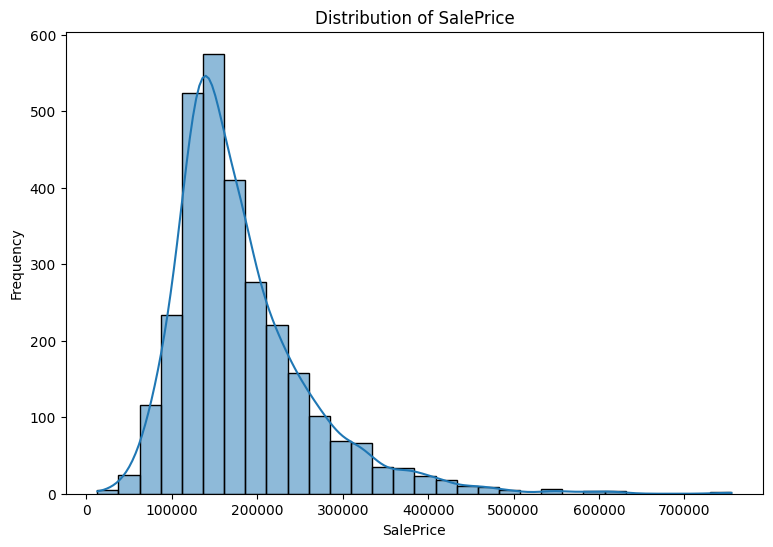

In [ ]:
# Define the orchestrator class
class UnivariateAnalyzer:
  def __init__(self, strategy: UnivariateAnalysisStrategy):
    self.strategy = strategy

  def set_strategy(self, strategy: UnivariateAnalysisStrategy):
    self.strategy = strategy

  def execute_analysis(self, predictor: pd.DataFrame, feature: str):
    self.strategy.analyze(predictor, feature)

# Analyzing a Numerical Feature
univariate_analyzer = UnivariateAnalyzer(NumericalUnivariateAnalysis())
univariate_analyzer.execute_analysis(predictor, 'SalePrice')

### Concrete Strategy for Categorical Features

In [ ]:
class CategoricalUnivariateAnalysis(UnivariateAnalysisStrategy):
  def analyze(self, predictor: pd.DataFrame, feature: str):
      plt.figure(figsize = (10, 6))
      sns.countplot(x = feature, data = predictor, palette = "muted")
      plt.title(f"Distribution of {feature}")
      plt.xlabel(feature)
      plt.ylabel("Count")
      plt.xticks(rotation = 45)
      plt.show()

/tmp/ipykernel_2273/3295078239.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = feature, data = predictor, palette = "muted")


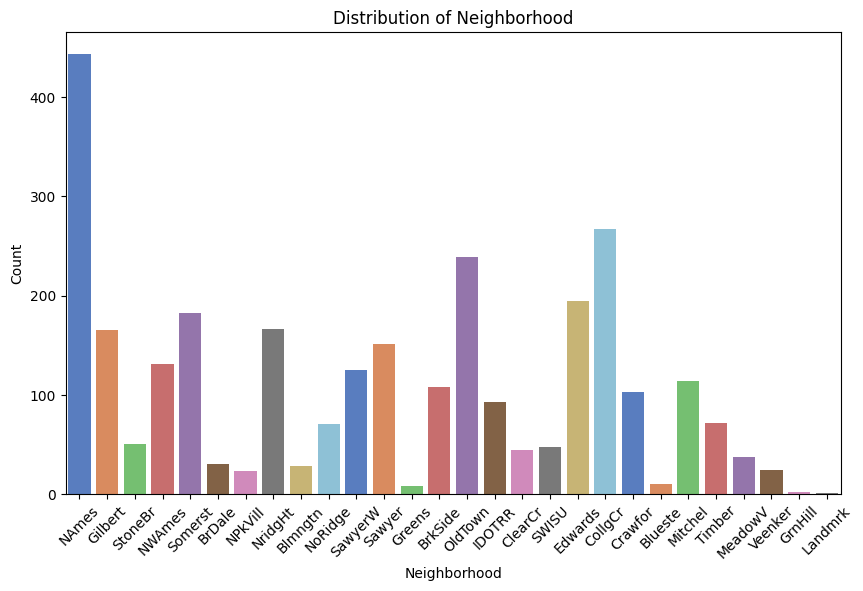

In [ ]:
# Analyzing a Categorical Feature
univariate_analyzer.set_strategy(CategoricalUnivariateAnalysis())
univariate_analyzer.execute_analysis(predictor, 'Neighborhood')

### **Bivariate Analysis**
### Analyzing the Relationship between Two Numerical Features

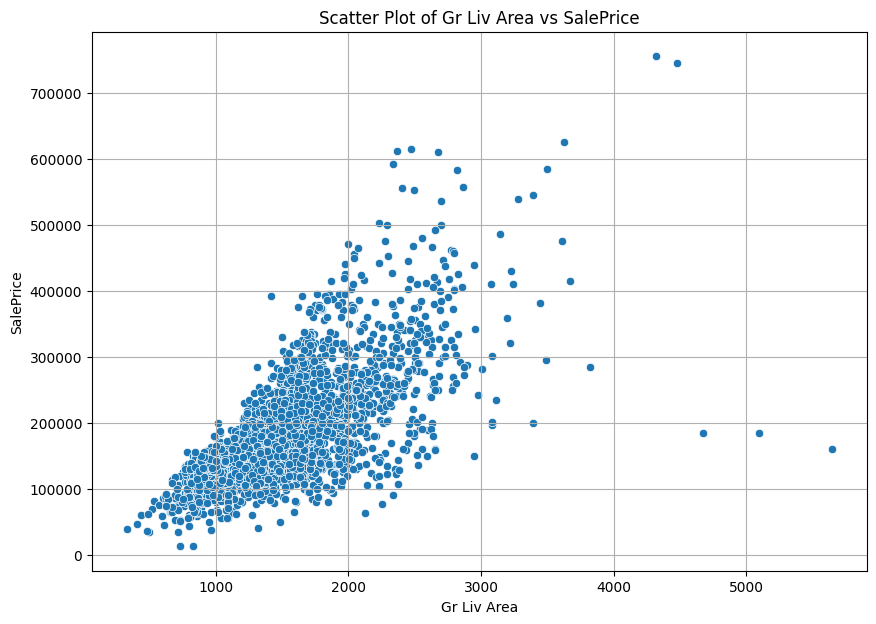

In [ ]:
from abc import ABC, abstractmethod

# Abstract Strategy for Bivariate Analysis
class BivariateAnalysisStrategy(ABC):
    @abstractmethod
    def analyze(self, predictor: pd.DataFrame, feature1: str, feature2: str):
        pass

# Concrete Strategy for Numerical vs Numerical Bivariate Analysis
class NumericalVsNumericalAnalysis(BivariateAnalysisStrategy):
    def analyze(self, predictor: pd.DataFrame, feature1: str, feature2: str):
        plt.figure(figsize=(10, 7))
        sns.scatterplot(x=feature1, y=feature2, data=predictor)
        plt.title(f'Scatter Plot of {feature1} vs {feature2}')
        plt.xlabel(feature1)
        plt.ylabel(feature2)
        plt.grid(True)
        plt.show()

# Define the orchestrator class for Bivariate Analysis
class BivariateAnalyzer:
    def __init__(self, strategy: BivariateAnalysisStrategy):
        self.strategy = strategy

    def set_strategy(self, strategy: BivariateAnalysisStrategy):
        self.strategy = strategy

    def execute_analysis(self, predictor: pd.DataFrame, feature1: str, feature2: str):
        self.strategy.analyze(predictor, feature1, feature2)

bivariate_analyzer = BivariateAnalyzer(NumericalVsNumericalAnalysis())
bivariate_analyzer.execute_analysis(predictor, 'Gr Liv Area', 'SalePrice')

### Analyzing the Relationship between a Categorical and a Numerical Feature

In [ ]:
# Concrete Strategy for Categorical vs Numerical Bivariate Analysis
class CategoricalVsNumericalAnalysis(BivariateAnalysisStrategy):
    def analyze(self, predictor: pd.DataFrame, feature1: str, feature2: str):
        plt.figure(figsize=(10, 7))
        sns.boxplot(x=feature1, y=feature2, data=predictor)
        plt.title(f'Boxplot Plot of {feature1} vs {feature2}')
        plt.xlabel(feature1)
        plt.ylabel(feature2)
        plt.xticks(rotation = 45)
        plt.show()

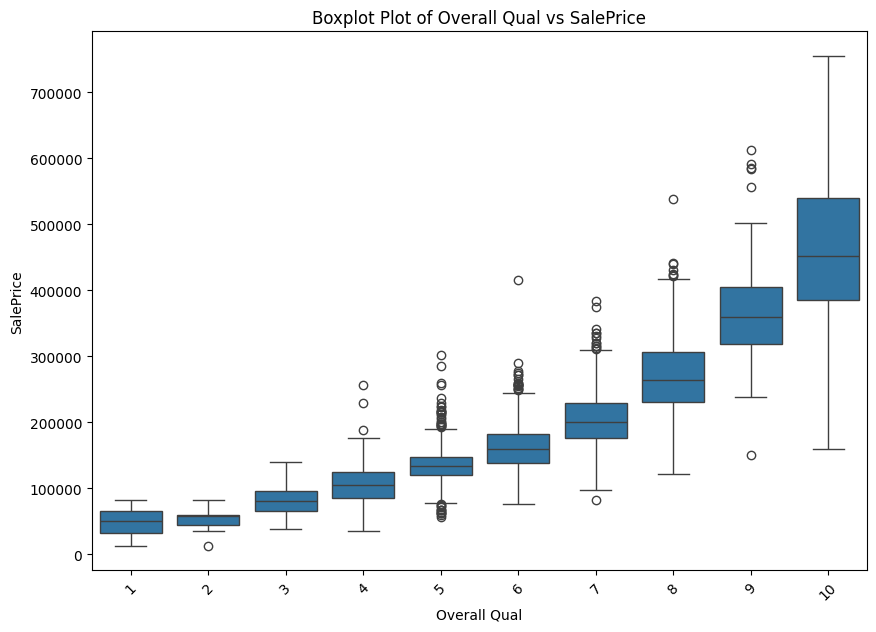

In [ ]:
bivariate_analyzer.set_strategy(CategoricalVsNumericalAnalysis())
bivariate_analyzer.execute_analysis(predictor, 'Overall Qual', 'SalePrice')

### Univariate Analysis Insights

1.  **SalePrice Distribution (Numerical Feature):**
    *   The histogram and KDE plot for `SalePrice` show a right-skewed distribution. This indicates that the majority of houses are sold at lower to moderate prices, with a longer tail extending towards higher price points, suggesting the presence of a few very expensive properties.
    *   The concentration of sales is roughly between $100,000 and $200,000, with fewer sales above $300,000. This skewness often requires transformation (e.g., log transformation) for models that assume normally distributed errors.

2.  **Neighborhood Distribution (Categorical Feature):**
    *   The `Neighborhood` count plot reveals that 'NAmes' (North Ames) is the most frequent neighborhood, followed by 'CollgCr', 'OldTown', and 'Edwards'.
    *   There is significant variation in the number of properties per neighborhood, with some neighborhoods having a very low count (e.g., 'GrnHill', 'Landmrk'). This uneven distribution suggests that 'Neighborhood' is a diverse feature and likely a strong predictor of `SalePrice`.

### Bivariate Analysis Insights

1.  **Gr Liv Area vs. SalePrice (Numerical vs Numerical):**
    *   The scatter plot of `Gr Liv Area` (Above Grade Living Area) against `SalePrice` shows a strong positive linear relationship. As the living area of a house increases, its `SalePrice` generally tends to increase.
    *   The points largely cluster around an upward-sloping trend line. However, there are some outliers, particularly houses with very large living areas that don't command extremely high prices, or conversely, some with moderate living areas that have high prices, indicating other influential factors or potential data points for further investigation.

2.  **Overall Qual vs. SalePrice (Categorical vs Numerical):**
    *   The boxplot illustrating `Overall Qual` (Overall Material and Finish Quality) vs. `SalePrice` demonstrates a very clear positive correlation. As the `Overall Qual` rating increases (from 1 to 10), the median `SalePrice` consistently rises.
    *   Houses with higher quality ratings (e.g., 8, 9, 10) exhibit higher median sale prices and also show a greater spread (larger IQR) in `SalePrice`, suggesting more variability among high-quality homes. This indicates that `Overall Qual` is a highly significant predictor of `SalePrice`.

### Summary of Univariate and Bivariate Analyses

#### 1. Key Predictors

*   **`Overall Qual`**: This is identified as a highly significant predictor, showing a clear positive correlation with `SalePrice`. Higher quality ratings consistently lead to higher median sale prices.
*   **`Gr Liv Area`**: Shows a strong positive linear relationship with `SalePrice`, indicating that larger living areas generally result in higher sale prices.
*   **`Neighborhood`**: This categorical feature is diverse and likely a strong predictor, as there's significant variation in the number of properties and implied price ranges across different neighborhoods.

#### 2. Data Distribution

*   **`SalePrice`**: Exhibits a right-skewed distribution, meaning most houses sell at lower to moderate prices, with a long tail indicating a few very expensive properties. This skewness suggests that data transformation (e.g., log transformation) might be beneficial for modeling.
*   **`Neighborhood`**: The distribution of properties across neighborhoods is uneven, with 'NAmes' being the most frequent, followed by 'CollgCr', 'OldTown', and 'Edwards'. Some neighborhoods have very few properties.

#### 3. Outliers

*   **`SalePrice`**: The right-skewed distribution of `SalePrice` inherently suggests the presence of outliers at the higher end of the price spectrum (very expensive properties).
*   **`Gr Liv Area` vs. `SalePrice`**: The scatter plot reveals some outliers, specifically houses with very large living areas that do not command exceptionally high prices, and some with moderate living areas that have surprisingly high prices. These points warrant further investigation.
*   **`Overall Qual` vs. `SalePrice`**: While showing a strong correlation, the boxplot indicates a wider spread of `SalePrice` (larger IQR) within higher `Overall Qual` categories, which could also imply more variability and potentially some outliers in those groups. Generally, the presence of individual points beyond the whiskers in the boxplots indicates outliers.

### **Multivariate Analysis**

In [ ]:
from abc import ABC, abstractmethod
import pandas as pd

# Abstract Strategy for Bivariate Analysis
class MultivariateAnalysisTemplate(ABC):
    @abstractmethod
    def analyze(self, predictor: pd.DataFrame):
        self.generate_correlation_heatmap(predictor)
        self.generate_pairplot(predictor)

    @abstractmethod
    def generate_correlation_heatmap(self, predictor: pd.DataFrame):
        pass

    @abstractmethod
    def generate_pairplot(self, predictor: pd.DataFrame):
        pass

class SimpleMultivariateAnalysis(MultivariateAnalysisTemplate):
    def analyze(self, predictor: pd.DataFrame):
        self.generate_correlation_heatmap(predictor)
        self.generate_pairplot(predictor)

    def generate_correlation_heatmap(self, predictor: pd.DataFrame):

        plt.figure(figsize = (8, 6))
        sns.heatmap(predictor.corr(), annot = True, fmt = ".2f", cmap = "coolwarm")
        plt.title("Correlation Heatmap")
        plt.xticks(rotation = 90)
        plt.yticks(rotation = 45)
        plt.show()

    def generate_pairplot(self, predictor: pd.DataFrame):

        sns.pairplot(predictor)
        plt.suptitle("Pair Plot of Selected Features")
        plt.show()

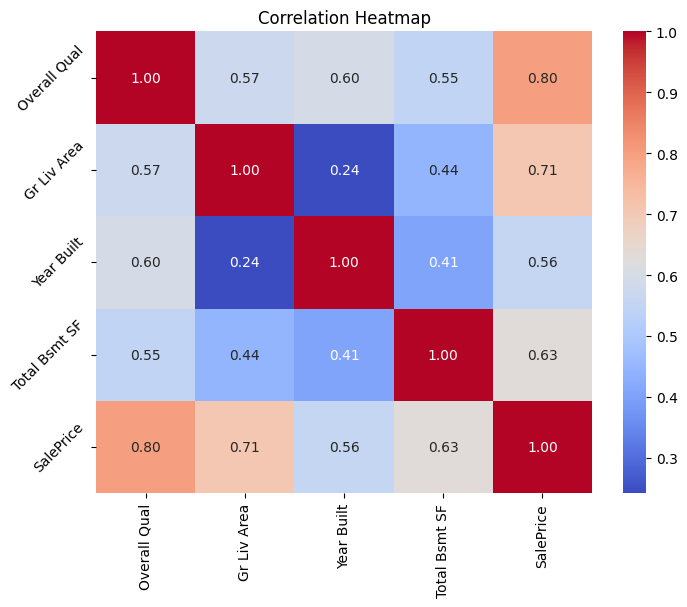

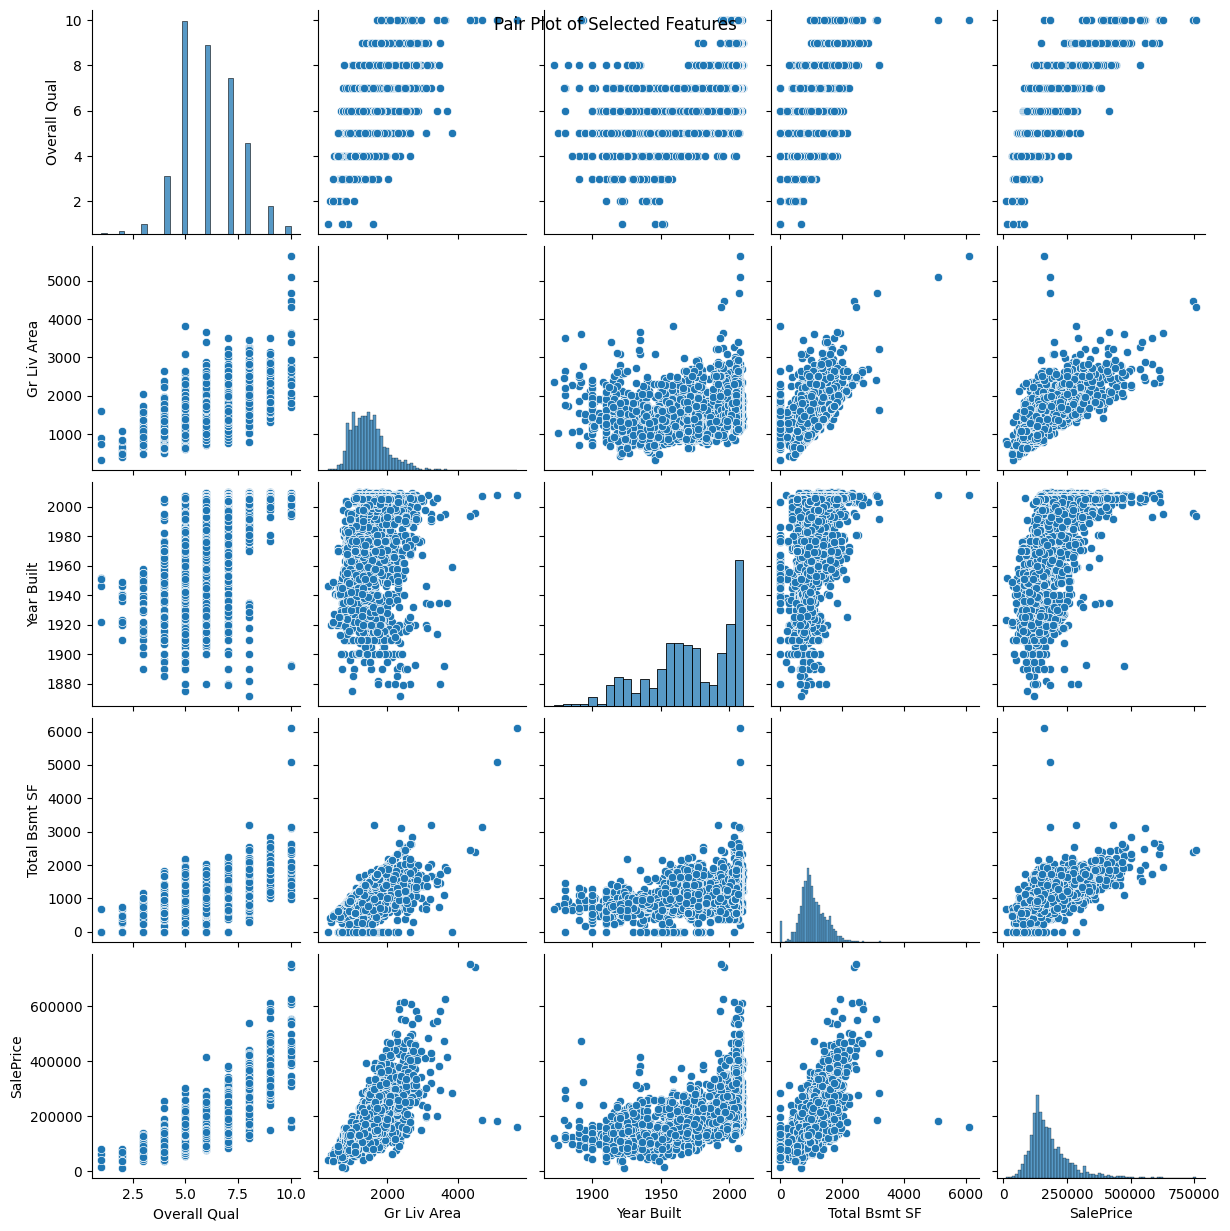

In [ ]:
# Define the orchestrator class for Multivariate Analysis
class MultivariateAnalyzer:
    def __init__(self, strategy: MultivariateAnalysisTemplate):
        self.strategy = strategy

    def set_strategy(self, strategy: MultivariateAnalysisTemplate):
        self.strategy = strategy

    def execute_analysis(self, predictor: pd.DataFrame, features: list):
        # Select only the features relevant for multivariate analysis
        data_for_analysis = predictor[features]
        self.strategy.analyze(data_for_analysis)

# Initialize The MultivariateAnalyzer with the SimpleMultivariateAnalysis
multivariate_analyzer = MultivariateAnalyzer(SimpleMultivariateAnalysis())

# Select Important Features for the Analysis
selected_features = ['Overall Qual', 'Gr Liv Area', 'Year Built', 'Total Bsmt SF', 'SalePrice']

# execute the multivariate analysis
multivariate_analyzer.execute_analysis(predictor, selected_features)

### Correlation Heatmap Insights

1.  **Strong Positive Correlation with `SalePrice`**:
    *   `Overall Qual` has the strongest positive correlation with `SalePrice` (0.80), indicating that higher overall quality of the house is a primary driver of its sale price.
    *   `Gr Liv Area` (above grade living area) also shows a very strong positive correlation (0.71) with `SalePrice`, confirming that larger living spaces command higher prices.
    *   `Total Bsmt SF` has a significant positive correlation (0.63) with `SalePrice`, suggesting that a larger total basement area contributes positively to the sale price.
    *   `Year Built` shows a moderate positive correlation (0.56) with `SalePrice`, implying that newer houses tend to fetch higher prices.

2.  **Inter-Feature Correlations (Multicollinearity)**:
    *   `Overall Qual` and `Gr Liv Area` have a moderate positive correlation (0.57), which is expected as higher quality homes often have larger living areas.
    *   `Total Bsmt SF` shows moderate correlations with `Overall Qual` (0.55) and `Gr Liv Area` (0.44), suggesting that larger homes with higher quality often have larger basements.
    *   `Year Built` has moderate correlations with `Overall Qual` (0.60), `Gr Liv Area` (0.24), and `Total Bsmt SF` (0.41).

3.  **Overall**: The heatmap clearly highlights the most influential features on `SalePrice` and also gives a sense of the relationships between the predictor variables themselves, which is crucial for understanding potential multicollinearity in modeling.

### Pair Plot Insights

1.  **Individual Feature Distributions (Diagonal Histograms)**:
    *   **`Overall Qual`**: The distribution is somewhat left-skewed, with a peak around 5-7, indicating that most houses fall into the average to good quality range.
    *   **`Gr Liv Area`**: Shows a right-skewed distribution, similar to `SalePrice`, with most houses having smaller to moderate living areas and a few very large ones.
    *   **`Year Built`**: The distribution appears to be multimodal or somewhat uniform with peaks corresponding to certain eras, reflecting periods of more active construction. There's a clear increase in frequency towards more recent years.
    *   **`Total Bsmt SF`**: The distribution is right-skewed, with a concentration of values at lower to moderate basement sizes, and a tail towards larger basements.
    *   **`SalePrice`**: As observed earlier, `SalePrice` is right-skewed, with most properties selling at lower to mid-range prices.

2.  **Relationships Between Features (Scatter Plots)**:
    *   **`Overall Qual` vs. `SalePrice`**: The scatter plot clearly shows an upward trend, with `SalePrice` generally increasing with `Overall Qual`. The spread of `SalePrice` also appears to increase at higher quality levels.
    *   **`Gr Liv Area` vs. `SalePrice`**: Displays a strong positive linear relationship. As `Gr Liv Area` increases, `SalePrice` generally increases. Some potential outliers are visible, especially houses with very large `Gr Liv Area` but not proportionally high `SalePrice`, or vice-versa.
    *   **`Year Built` vs. `SalePrice`**: There's a visible positive trend; newer houses tend to have higher sale prices, though the relationship is not as strictly linear as with `Gr Liv Area`. Older homes have a wider range of prices.
    *   **`Total Bsmt SF` vs. `SalePrice`**: Shows a positive correlation, where larger basements generally correspond to higher sale prices. The density of points is concentrated at lower basement sizes.
    *   **`Overall Qual` vs. `Gr Liv Area`**: A positive relationship is evident, suggesting that higher quality houses often have larger living areas. However, there's a significant spread, meaning quality isn't solely dependent on size.
    *   **`Year Built` vs. `Total Bsmt SF`**: Newer homes generally have larger basements, but this relationship is not very strong.

3.  **Outliers**: Consistent with previous observations, the scatter plots for `SalePrice` vs. `Gr Liv Area` and `SalePrice` vs. `Total Bsmt SF` show points that deviate from the general trend, indicating potential outliers that may warrant further investigation or special handling during modeling.

### Dealing with Multicollinearity

**Problem**: High correlation between independent variables (e.g., `Overall Qual` and `Gr Liv Area`) can make it difficult for linear models to determine the individual impact of each predictor. This can lead to unstable model coefficients.

**How to Deal (if using models sensitive to multicollinearity like linear regression)**:

*   **Feature Removal**: If two features are very highly correlated and one is less important or redundant, consider removing one of them.
*   **Combine Features**: Create a new feature by combining the highly correlated ones (e.g., through Principal Component Analysis).
*   **Regularization**: Techniques like Ridge or Lasso regression can handle multicollinearity by penalizing large coefficients.
*   **Robust Models**: Tree-based models (like Random Forest or Gradient Boosting) are generally less affected by multicollinearity, so if using these, multicollinearity might be less of a concern.

### Strategies for Feature Engineering

**Purpose**: Create new, more informative features from existing ones to improve model performance. This step can provide more relevant information or capture complex relationships.

**Examples of Feature Engineering based on our data**:

*   **Age of Property**: Derive `Age of House` from `Yr Sold - Year Built` or `Years Since Remodel` from `Yr Sold - Year Remod/Add`. Newer homes often command higher prices.
*   **Total Living Area**: Combine `Gr Liv Area`, `Total Bsmt SF`, `1st Flr SF`, `2nd Flr SF` into a single `Total SF` feature to represent the overall size.
*   **Total Bathrooms**: Sum `Full Bath`, `Half Bath`, `Bsmt Full Bath`, `Bsmt Half Bath` to get a comprehensive `Total Bathrooms` count.
*   **Outdoor Space**: Combine `Wood Deck SF`, `Open Porch SF`, `Enclosed Porch`, `3Ssn Porch`, `Screen Porch` to create a `Total Porch SF` or `Total Outdoor SF` feature.
*   **Binary Indicators**: For rare amenities (like `Pool QC`), create a simple binary feature `HasPool` (1 if 'Pool QC' is not 'None', 0 otherwise). This simplifies the feature while retaining its presence/absence information.
*   **Interaction Terms**: Consider creating interaction terms like `Overall Qual * Gr Liv Area` to capture that a large, high-quality house might be worth more than the sum of its individual parts.

### Handling Outliers

**Problem**: Extreme values (outliers) in features like `SalePrice`, `Gr Liv Area`, or `Total Bsmt SF` can disproportionately influence model training and lead to biased predictions.

**How to Deal**:

*   **Investigation**: First, determine if outliers are data entry errors or genuine extreme values. If they are errors, correct or remove them.
*   **Transformation**: Apply transformations like `log()` or `sqrt()` to highly skewed features (`SalePrice`, `Gr Liv Area`, `Total Bsmt SF`). This compresses the range of values and often makes the distribution more symmetric, reducing the impact of large outliers.
*   **Capping/Winsorization**: Limit extreme values to a certain percentile (e.g., replace values above the 99th percentile with the value at the 99th percentile, or values below the 1st percentile with the value at the 1st percentile). This retains the data points but reduces their extreme influence.
*   **Robust Models**: Some machine learning models are inherently more robust to outliers, such as tree-based models (Random Forest, Gradient Boosting) or robust regression techniques, which can be chosen if outliers are prevalent and difficult to remove or transform effectively.

### **Data Ingestion Step**

In [ ]:
%%writefile {src_dir}/ingest_data.py

import pandas as pd

class CSVDataIngestor:
    """Ingests data from a CSV file."""

    def ingest(self, data_path: str) -> pd.DataFrame:
        """Reads a CSV file into a Pandas DataFrame.

        Args:
            data_path: Path to the CSV data file.

        Returns:
            A Pandas DataFrame containing the ingested data.
        """
        try:
            data = pd.read_csv(data_path)
            return data
        except Exception as e:
            print(f"Error ingesting data from {data_path}: {e}")
            raise

Writing src/ingest_data.py


In [ ]:
%%writefile {src_dir}/data_ingestion_step.py

from zenml import step
import pandas as pd

from .ingest_data import CSVDataIngestor

@step
def ingest_data_step(data_path: str) -> pd.DataFrame:
    """Data ingestion step to read data from a CSV file.

    Args:
        data_path: Path to the data file.

    Returns:
        A Pandas DataFrame containing the ingested data.
    """
    ingestor = CSVDataIngestor()
    predictor = ingestor.ingest(data_path)
    return predictor

Writing src/data_ingestion_step.py


In [ ]:
%%writefile {src_dir}/data_ingestion_step.py

import pandas as pd

from .ingest_data import CSVDataIngestor

def ingest_data_step(data_path: str) -> pd.DataFrame:
    """Data ingestion step to read data from a CSV file.

    Args:
        data_path: Path to the data file.

    Returns:
        A Pandas DataFrame containing the ingested data.
    """
    ingestor = CSVDataIngestor()
    predictor = ingestor.ingest(data_path)
    return predictor

Overwriting src/data_ingestion_step.py


### **Handle Missing Values Step**

In [ ]:
import pandas as pd
from abc import ABC, abstractmethod
from typing import Dict, Any

# --- Re-defining handle_missing_values.py content (from deleted cell 27d94025) ---
class MissingValueStrategy(ABC):
    """Abstract base class for missing value handling strategies."""

    @abstractmethod
    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Applies the missing value handling strategy to the data."""
        pass


class DropMissingValuesStrategy(MissingValueStrategy):
    """Strategy to drop rows or columns with missing values."""

    def __init__(self, axis: int = 0):
        """Initializes the strategy.

        Args:
            axis: 0 to drop rows, 1 to drop columns.
        """
        self.axis = axis

    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Drops rows or columns with missing values.

        Args:
            data: The input Pandas DataFrame.

        Returns:
            A Pandas DataFrame with missing values dropped.
        """
        return data.dropna(axis=self.axis)


class ImputeWithMeanStrategy(MissingValueStrategy):
    """Strategy to impute missing numerical values with the mean of their column."""

    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Imputes missing numerical values with the mean.

        Args:
            data: The input Pandas DataFrame.

        Returns:
            A Pandas DataFrame with numerical missing values imputed by the mean.
        """
        numerical_cols = data.select_dtypes(include=['number']).columns
        for col in numerical_cols:
            if data[col].isnull().any():
                data[col] = data[col].fillna(data[col].mean())
        return data


class ImputeWithMedianStrategy(MissingValueStrategy):
    """Strategy to impute missing numerical values with the median of their column."""

    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Imputes missing numerical values with the median.

        Args:
            data: The input Pandas DataFrame.

        Returns:
            A Pandas DataFrame with numerical missing values imputed by the median.
        """
        numerical_cols = data.select_dtypes(include=['number']).columns
        for col in numerical_cols:
            if data[col].isnull().any():
                data[col] = data[col].fillna(data[col].median())
        return data


class ImputeWithModeStrategy(MissingValueStrategy):
    """Strategy to impute missing categorical values with the mode of their column."""

    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Imputes missing categorical values with the mode.

        Args:
            data: The input Pandas DataFrame.

        Returns:
            A Pandas DataFrame with categorical missing values imputed by the mode.
        """
        categorical_cols = data.select_dtypes(include=['object', 'category']).columns
        for col in categorical_cols:
            if data[col].isnull().any():
                # Use .mode()[0] to handle cases where there might be multiple modes
                data[col] = data[col].fillna(data[col].mode()[0])
        return data


class ImputeWithConstantStrategy(MissingValueStrategy):
    """Strategy to impute missing values with a specified constant."""

    def __init__(self, value_map: dict):
        """Initializes the strategy with a dictionary mapping column names to constant values.

        Args:
            value_map: A dictionary where keys are column names and values are the constants to impute `NaN`s with.
        """
        self.value_map = value_map

    def handle(self, data: pd.DataFrame) -> pd.DataFrame:
        """Imputes missing values with specified constants.

        Args:
            data: The input Pandas DataFrame.

        Returns:
            A Pandas DataFrame with missing values imputed by constants.
        """
        for col, value in self.value_map.items():
            if col in data.columns and data[col].isnull().any():
                data[col] = data[col].fillna(value)
        return data

# --- Re-defining handle_missing_values_step.py content (from deleted cell c478d706) ---
def handle_missing_values_step(
    data: pd.DataFrame,
    categorical_imputation_values: Dict[str, Any],
    numerical_imputation_strategy_type: str
) -> pd.DataFrame:
    """Handles missing values in the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        categorical_imputation_values: A dictionary where keys are column names
                                     and values are the constants to impute `NaN`s with.
        numerical_imputation_strategy_type: The type of strategy to use for numerical columns
                                          (e.g., 'median', 'mean').

    Returns:
        A Pandas DataFrame with missing values handled.
    """
    processed_data = data.copy()

    # 1. Handle categorical missing values with a constant (e.g., 'None')
    constant_imputer = ImputeWithConstantStrategy(categorical_imputation_values)
    processed_data = constant_imputer.handle(processed_data)

    # 2. Handle any remaining categorical missing values with mode imputation
    # Identify categorical columns that still have missing values
    remaining_categorical_cols_with_nans = processed_data.select_dtypes(include=['object', 'category']).columns[
        processed_data.select_dtypes(include=['object', 'category']).isnull().any()
    ].tolist()

    for col in remaining_categorical_cols_with_nans:
        if processed_data[col].isnull().any():
            processed_data[col] = processed_data[col].fillna(processed_data[col].mode()[0])

    # 3. Handle numerical missing values based on strategy type
    if numerical_imputation_strategy_type == 'median':
        numerical_imputer = ImputeWithMedianStrategy()
    elif numerical_imputation_strategy_type == 'mean':
        numerical_imputer = ImputeWithMeanStrategy()
    else:
        raise ValueError(f"Unsupported numerical imputation strategy: {numerical_imputation_strategy_type}")

    processed_data = numerical_imputer.handle(processed_data)

    return processed_data

# --- Re-defining categorical_imputation_values (from deleted cell 1e514c99) ---
categorical_imputation_values = {
    'Alley': 'None',
    'Fireplace Qu': 'None',
    'Pool QC': 'None',
    'Fence': 'None',
    'Misc Feature': 'None',
    'Mas Vnr Type': 'None',
    'Bsmt Qual': 'None',
    'Bsmt Cond': 'None',
    'Bsmt Exposure': 'None',
    'BsmtFin Type 1': 'None',
    'BsmtFin Type 2': 'None',
    'Garage Type': 'None',
    'Garage Finish': 'None',
    'Garage Qual': 'None',
    'Garage Cond': 'None'
}

# Handling Missing Values Step
filled_data = handle_missing_values_step(predictor, categorical_imputation_values, numerical_imputation_strategy_type='median')

In [ ]:
# Verify missing values in the processed DataFrame
missing_after_imputation = filled_data.isnull().sum()
missing_after_imputation = missing_after_imputation[missing_after_imputation > 0]

if not missing_after_imputation.empty:
    print("Columns that still have missing values after imputation:")
    display(missing_after_imputation)
else:
    print("All missing values have been successfully handled in 'filled_data'.")

All missing values have been successfully handled in 'filled_data'.


In [ ]:
filled_data.isna().sum()

,0
Order,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,0
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


### Summary: Handling Missing Values

This step successfully addressed all missing values in the dataset. Categorical columns with significant missingness (e.g., 'Alley', 'Pool QC', 'Fence') were imputed with a 'None' category, indicating the absence of that feature. Numerical columns with missing values (e.g., 'Lot Frontage', 'Garage Yr Blt') were imputed using the median strategy. This comprehensive imputation ensures that the dataset is now complete and ready for further processing, preventing errors in subsequent modeling steps.

###  **Feature Engineering Step**

In [ ]:
%%writefile {src_dir}/feature_engineering.py

import pandas as pd
from abc import ABC, abstractmethod
import numpy as np

class FeatureEngineeringStrategy(ABC):
    """Abstract base class for feature engineering strategies."""

    @abstractmethod
    def apply(self, data: pd.DataFrame, features: list) -> pd.DataFrame:
        """Applies the feature engineering strategy to the data."""
        pass

class LogTransformationStrategy(FeatureEngineeringStrategy):
    """Applies logarithmic transformation to specified numerical features."""

    def apply(self, data: pd.DataFrame, features: list) -> pd.DataFrame:
        """Applies log transformation to the given features.

        Args:
            data: The input Pandas DataFrame.
            features: A list of feature names to apply log transformation to.

        Returns:
            A Pandas DataFrame with specified features log-transformed.
        """
        processed_data = data.copy()
        for feature in features:
            if feature in processed_data.columns and pd.api.types.is_numeric_dtype(processed_data[feature]):
                # Add a small constant to avoid log(0) if necessary, or handle zeros explicitly
                processed_data[f'{feature}_log'] = np.log1p(processed_data[feature])
            else:
                print(f"Warning: Feature '{feature}' not found or not numerical. Skipping log transformation.")
        return processed_data


Writing src/feature_engineering.py


In [ ]:
%%writefile {src_dir}/feature_engineering_step.py

import pandas as pd
from typing import Literal
from .feature_engineering import LogTransformationStrategy

def feature_engineering_step(
    data: pd.DataFrame,
    strategy: Literal["log"],
    features: list
) -> pd.DataFrame:
    """Applies feature engineering techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        strategy: The type of feature engineering strategy to apply (e.g., 'log').
        features: A list of feature names to apply the strategy to.

    Returns:
        A Pandas DataFrame with new engineered features.
    """
    processed_data = data.copy()

    if strategy == "log":
        log_transformer = LogTransformationStrategy()
        processed_data = log_transformer.apply(processed_data, features)
    else:
        raise ValueError(f"Unsupported feature engineering strategy: {strategy}")

    return processed_data


Writing src/feature_engineering_step.py


In [ ]:
import os
import sys

# Add src directory to Python path if not already there
if 'src' not in sys.path:
    sys.path.insert(0, 'src')

# Clear and reload modules to ensure the latest changes are picked up
import importlib

# List of modules to clear from sys.modules
modules_to_clear = [
    'feature_engineering',
    'feature_engineering_step',
]

for module_name in modules_to_clear:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Import the feature_engineering_step function as a submodule of src
from src.feature_engineering_step import feature_engineering_step

# Feature Engineering Step
engineered_data = feature_engineering_step(
    filled_data, strategy="log", features=["Gr Liv Area", "SalePrice"]
)


### Summary: Feature Engineering Step

In this step, `Log Transformation` was applied to the 'Gr Liv Area' and 'SalePrice' features, resulting in new columns 'Gr Liv Area_log' and 'SalePrice_log'. This transformation was performed to reduce the skewness in their distributions, which was observed during the univariate analysis. Log-transformed target variables often lead to better model performance and meet the assumptions of linear models more closely. The `engineered_data` DataFrame now contains these transformed features.

### **Outlier Detection and Handling**

In [ ]:
%%writefile {src_dir}/outlier_detection.py

import pandas as pd
import numpy as np
from abc import ABC, abstractmethod

class OutlierDetectionStrategy(ABC):
    """Abstract base class for outlier detection strategies."""

    @abstractmethod
    def detect_and_handle(self, data: pd.DataFrame, column_name: str) -> pd.DataFrame:
        """Applies the outlier detection and handling strategy to the data."""
        pass

class IQROutlierDetectionStrategy(OutlierDetectionStrategy):
    """Concrete strategy to detect and handle outliers using the IQR method."""

    def __init__(self, factor: float = 1.5):
        """Initializes the strategy with an IQR factor.

        Args:
            factor: The multiplier for the IQR to define outlier bounds.
        """
        self.factor = factor

    def detect_and_handle(self, data: pd.DataFrame, column_name: str) -> pd.DataFrame:
        """Detects and handles outliers in a specified column using the IQR method.
        Outliers are capped to the upper and lower bounds.

        Args:
            data: The input Pandas DataFrame.
            column_name: The name of the column to detect outliers in.

        Returns:
            A Pandas DataFrame with outliers in the specified column capped.
        Raises:
            ValueError: If the specified column is not found or is not numerical.
        """
        if column_name not in data.columns:
            raise ValueError(f"Column '{column_name}' not found in the DataFrame.")
        if not pd.api.types.is_numeric_dtype(data[column_name]):
            raise ValueError(f"Column '{column_name}' is not numerical.")

        processed_data = data.copy()
        Q1 = processed_data[column_name].quantile(0.25)
        Q3 = processed_data[column_name].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - self.factor * IQR
        upper_bound = Q3 + self.factor * IQR

        # Cap outliers
        processed_data[column_name] = np.where(
            processed_data[column_name] < lower_bound, lower_bound,
            np.where(processed_data[column_name] > upper_bound, upper_bound,
                     processed_data[column_name])
        )
        return processed_data

Writing src/outlier_detection.py


In [ ]:
%%writefile {src_dir}/outlier_detection_step.py

import pandas as pd
from typing import Literal
from .outlier_detection import IQROutlierDetectionStrategy

def outlier_detection_step(
    data: pd.DataFrame,
    column_name: str,
    strategy: Literal["iqr"] = "iqr",
    iqr_factor: float = 1.5
) -> pd.DataFrame:
    """Applies outlier detection and handling techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        column_name: The name of the column to detect outliers in.
        strategy: The type of outlier detection strategy to apply (e.g., 'iqr').
        iqr_factor: The multiplier for the IQR to define outlier bounds (only for 'iqr' strategy).

    Returns:
        A Pandas DataFrame with outliers handled.
    """
    processed_data = data.copy()

    if strategy == "iqr":
        iqr_detector = IQROutlierDetectionStrategy(factor=iqr_factor)
        processed_data = iqr_detector.detect_and_handle(processed_data, column_name)
    else:
        raise ValueError(f"Unsupported outlier detection strategy: {strategy}")

    return processed_data

Writing src/outlier_detection_step.py


In [ ]:
import os
import sys
import importlib

# Add src directory to Python path if not already there
if 'src' not in sys.path:
    sys.path.insert(0, 'src')

# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_outlier = [
    'outlier_detection',
    'outlier_detection_step'
]

for module_name in modules_to_clear_outlier:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Import the outlier_detection_step function
from src.outlier_detection_step import outlier_detection_step

# Outlier Detection Step
clean_data = outlier_detection_step(engineered_data, column_name="SalePrice")

### Summary: Outlier Detection & Handling Step

This step focused on handling outliers in the 'SalePrice' column using the IQR (Interquartile Range) method. Outliers were detected and then capped to the upper and lower bounds defined by the IQR factor (typically 1.5). This strategy helps to mitigate the impact of extreme values on model training without removing data points entirely. The resulting `clean_data` DataFrame now has its 'SalePrice' values adjusted, leading to a more robust target variable for modeling.

### **Multicollinearity Handling Step**

In [ ]:
%%writefile {src_dir}/multicollinearity.py

import pandas as pd
from abc import ABC, abstractmethod
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

class MulticollinearityStrategy(ABC):
    """Abstract base class for multicollinearity handling strategies."""

    @abstractmethod
    def handle_multicollinearity(self, data: pd.DataFrame, target_column: str, threshold: float = 5.0) -> pd.DataFrame:
        """Applies the multicollinearity handling strategy to the data.

        Args:
            data: The input Pandas DataFrame.
            target_column: The name of the target column to be excluded from VIF calculation.
            threshold: The VIF threshold for dropping features.

        Returns:
            A Pandas DataFrame with multicollinear features handled.
        """
        pass

class VIFMulticollinearityStrategy(MulticollinearityStrategy):
    """Concrete strategy to handle multicollinearity using VIF (Variance Inflation Factor)."""

    def handle_multicollinearity(self, data: pd.DataFrame, target_column: str, threshold: float = 5.0) -> pd.DataFrame:
        """Detects and handles multicollinearity in numerical features using VIF.

        Args:
            data: The input Pandas DataFrame.
            target_column: The name of the target column to be excluded from VIF calculation.
            threshold: The VIF threshold for dropping features. Features with VIF above this
                       threshold will be considered for removal.

        Returns:
            A Pandas DataFrame with highly multicollinear features removed.
        """
        # Exclude the target column from VIF calculation
        features_for_vif = data.drop(columns=[target_column], errors='ignore').select_dtypes(include=['number'])

        # Drop columns with NaN values that might prevent VIF calculation
        features_for_vif = features_for_vif.dropna(axis=1)

        if features_for_vif.empty:
            print("No numerical columns for VIF calculation or all dropped due to NaNs after excluding target.")
            return data

        # Add a constant to the data for VIF calculation
        X = add_constant(features_for_vif, has_constant='add')

        # Calculate VIF for each feature
        vif_data = pd.DataFrame()
        vif_data["feature"] = X.columns
        vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

        # Drop the constant column from VIF data for analysis
        vif_data = vif_data[vif_data['feature'] != 'const']

        highly_multicollinear_features = vif_data[vif_data['VIF'] > threshold].sort_values(by='VIF', ascending=False)

        processed_data = data.copy()
        if not highly_multicollinear_features.empty:
            print(f"Features with VIF > {threshold}:")
            print(highly_multicollinear_features)
            features_to_drop = highly_multicollinear_features['feature'].tolist()
            # Remove features from the original DataFrame (only numerical ones that were processed)
            for feature in features_to_drop:
                if feature in processed_data.columns:
                    processed_data = processed_data.drop(columns=[feature])
            print(f"Dropped {len(features_to_drop)} features due to high multicollinearity: {features_to_drop}")
        else:
            print("No highly multicollinear features found above the threshold.")

        return processed_data

Writing src/multicollinearity.py


In [ ]:
%%writefile {src_dir}/multicollinearity_step.py

import pandas as pd
from typing import Literal
from .multicollinearity import VIFMulticollinearityStrategy

def multicollinearity_step(
    data: pd.DataFrame,
    target_column: str,
    strategy: Literal["vif"] = "vif",
    threshold: float = 5.0
) -> pd.DataFrame:
    """Applies multicollinearity handling techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        target_column: The name of the target column to be excluded from VIF calculation.
        strategy: The type of multicollinearity strategy to apply (e.g., 'vif').
        threshold: The VIF threshold for dropping features (only for 'vif' strategy).

    Returns:
        A Pandas DataFrame with multicollinear features handled.
    """
    processed_data = data.copy()

    if strategy == "vif":
        vif_handler = VIFMulticollinearityStrategy()
        processed_data = vif_handler.handle_multicollinearity(processed_data, target_column, threshold)
    else:
        raise ValueError(f"Unsupported multicollinearity strategy: {strategy}")

    return processed_data

Writing src/multicollinearity_step.py


In [ ]:
import os
import sys
import importlib

# Add src directory to Python path if not already there
if 'src' not in sys.path:
    sys.path.insert(0, 'src')

# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_multicollinearity = [
    'multicollinearity',
    'multicollinearity_step'
]

for module_name in modules_to_clear_multicollinearity:
    full_module_path = f"src.{module_name}"
    if full_module_path in sys.modules:
        print(f"Deleting {full_module_path} from sys.modules")
        del sys.modules[full_module_path]

# Import the multicollinearity_step function
from src.multicollinearity_step import multicollinearity_step

# Explicitly reload if the module is still in sys.modules after deletion (defensive programming)
# This helps ensure the very latest version from disk is used.
if 'src.multicollinearity_step' in sys.modules:
    print("Reloading src.multicollinearity_step")
    importlib.reload(sys.modules['src.multicollinearity_step'])
    # Re-import specific function after reload to ensure we get the updated version
    from src.multicollinearity_step import multicollinearity_step

# Verify the signature of the imported function (for debugging)
import inspect
print(f"Signature of multicollinearity_step: {inspect.signature(multicollinearity_step)}")

# Multicollinearity Handling Step
# First, drop the original 'SalePrice' column from the data, as 'SalePrice_log' is our intended target.
data_for_multicollinearity = clean_data.drop(columns=['SalePrice'], errors='ignore')
# Ensure 'SalePrice_log' is excluded from multicollinearity checks among predictors
processed_data = multicollinearity_step(data_for_multicollinearity, target_column="SalePrice_log", strategy="vif", threshold=5.0)


Reloading src.multicollinearity_step
Signature of multicollinearity_step: (data: pandas.core.frame.DataFrame, target_column: str, strategy: Literal['vif'] = 'vif', threshold: float = 5.0) -> pandas.core.frame.DataFrame


/usr/local/lib/python3.12/dist-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Features with VIF > 5.0:
            feature           VIF
15       1st Flr SF           inf
18      Gr Liv Area           inf
17  Low Qual Fin SF           inf
16       2nd Flr SF           inf
11     BsmtFin SF 1  2.585092e+04
14    Total Bsmt SF  2.416491e+04
13      Bsmt Unf SF  2.405272e+04
12     BsmtFin SF 2  3.564168e+03
1             Order  7.925081e+01
38          Yr Sold  7.715998e+01
39  Gr Liv Area_log  2.151866e+01
28      Garage Cars  5.903512e+00
29      Garage Area  5.676919e+00
Dropped 13 features due to high multicollinearity: ['1st Flr SF', 'Gr Liv Area', 'Low Qual Fin SF', '2nd Flr SF', 'BsmtFin SF 1', 'Total Bsmt SF', 'Bsmt Unf SF', 'BsmtFin SF 2', 'Order', 'Yr Sold', 'Gr Liv Area_log', 'Garage Cars', 'Garage Area']


### Summary: Multicollinearity Detection & Handling

This step addressed multicollinearity among numerical features using the Variance Inflation Factor (VIF) strategy. Features with a VIF score above the threshold of 5.0 were identified and removed from the dataset. Importantly, the target variable `SalePrice_log` was explicitly excluded from this process to ensure it was not accidentally dropped. Several highly correlated features (e.g., `1st Flr SF`, `Gr Liv Area` components, some `BsmtFin SF` features, `Order`, `Yr Sold`, `Gr Liv Area_log`, `Garage Cars`, `Garage Area`) were dropped, resulting in the `processed_data` DataFrame. This helps to create a more stable and interpretable model, especially for linear regression algorithms.

### **Categorical Features Encoding**

In [ ]:
import os
import sys
import importlib
import pandas as pd
from abc import ABC, abstractmethod
from typing import Literal

# Ensure 'src' directory exists and is in Python path
src_dir = 'src'
os.makedirs(src_dir, exist_ok=True)
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

# --- Content for src/categorical_encoding.py ---
categorical_encoding_content = '''
import pandas as pd
from abc import ABC, abstractmethod

class CategoricalEncodingStrategy(ABC):
    """Abstract base class for categorical encoding strategies."""

    @abstractmethod
    def encode(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies the encoding strategy to specified categorical columns."""
        pass

class OneHotEncodingStrategy(CategoricalEncodingStrategy):
    """Concrete strategy for One-Hot Encoding using pandas get_dummies."""

    def encode(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies One-Hot Encoding to the specified columns.

        Args:
            data: The input Pandas DataFrame.
            columns: A list of column names to be One-Hot Encoded.

        Returns:
            A Pandas DataFrame with specified columns One-Hot Encoded.
        """
        processed_data = data.copy()
        processed_data = pd.get_dummies(processed_data, columns=columns, drop_first=True)
        return processed_data
'''

# Write the content to src/categorical_encoding.py
with open(os.path.join(src_dir, 'categorical_encoding.py'), 'w') as f:
    f.write(categorical_encoding_content)
print(f"Written {src_dir}/categorical_encoding.py")

# --- Content for src/categorical_encoding_step.py ---
categorical_encoding_step_content = '''
import pandas as pd
from typing import Literal
from .categorical_encoding import OneHotEncodingStrategy

def categorical_encoding_step(
    data: pd.DataFrame,
    strategy: Literal["one_hot"] = "one_hot",
    columns: list = None
) -> pd.DataFrame:
    """Applies categorical encoding techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        strategy: The type of encoding strategy to apply (e.g., 'one_hot').
        columns: A list of column names to encode. If None, all object/category dtype columns will be encoded.

    Returns:
        A Pandas DataFrame with categorical features encoded.
    """
    processed_data = data.copy()

    if columns is None:
        # Identify all categorical columns if not specified
        columns = processed_data.select_dtypes(include=['object', 'category']).columns.tolist()

    if not columns:
        print("No categorical columns to encode or 'columns' list is empty.")
        return processed_data

    if strategy == "one_hot":
        encoder = OneHotEncodingStrategy()
        processed_data = encoder.encode(processed_data, columns)
    else:
        raise ValueError(f"Unsupported encoding strategy: {strategy}")

    return processed_data
'''

# Write the content to src/categorical_encoding_step.py
with open(os.path.join(src_dir, 'categorical_encoding_step.py'), 'w') as f:
    f.write(categorical_encoding_step_content)
print(f"Written {src_dir}/categorical_encoding_step.py")


# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_encoding = [
    'categorical_encoding',
    'categorical_encoding_step'
]

for module_name in modules_to_clear_encoding:
    full_module_path = f"src.{module_name}"
    if full_module_path in sys.modules:
        print(f"Deleting {full_module_path} from sys.modules")
        del sys.modules[full_module_path]

# Import the categorical_encoding_step function
from src.categorical_encoding_step import categorical_encoding_step

# Explicitly reload if the module is still in sys.modules after deletion
if 'src.categorical_encoding_step' in sys.modules:
    print("Reloading src.categorical_encoding_step")
    importlib.reload(sys.modules['src.categorical_encoding_step'])
    from src.categorical_encoding_step import categorical_encoding_step

# Perform One-Hot Encoding on all remaining object-type columns
# The multicollinearity step might have removed some columns, so we re-identify categorical columns.
# 'processed_data' is expected to be available from previous steps.
encoded_data = categorical_encoding_step(processed_data, strategy="one_hot")

print("Shape after categorical encoding:", encoded_data.shape)
display(encoded_data.head())

Written src/categorical_encoding.py
Written src/categorical_encoding_step.py
Reloading src.categorical_encoding_step
Shape after categorical encoding: (2930, 266)


,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Bsmt Full Bath,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,526301100,20,141.0,31770,6,5,1960,1960,112.0,1.0,...,False,False,False,False,True,False,False,False,True,False
1,526350040,20,80.0,11622,5,6,1961,1961,0.0,0.0,...,False,False,False,False,True,False,False,False,True,False
2,526351010,20,81.0,14267,6,6,1958,1958,108.0,0.0,...,False,False,False,False,True,False,False,False,True,False
3,526353030,20,93.0,11160,7,5,1968,1968,0.0,1.0,...,False,False,False,False,True,False,False,False,True,False
4,527105010,60,74.0,13830,5,5,1997,1998,0.0,0.0,...,False,False,False,False,True,False,False,False,True,False


### Summary: Categorical Encoding

In this step, all identified object-type (categorical) columns in the `processed_data` DataFrame were transformed using One-Hot Encoding. This converts categorical variables into a numerical format (binary columns) suitable for machine learning algorithms. The `encoded_data` DataFrame now contains these newly created boolean columns. One-Hot Encoding ensures that the model doesn't assume any ordinal relationship between categories where none exists.

In [ ]:
%%writefile {src_dir}/categorical_encoding.py

import pandas as pd
from abc import ABC, abstractmethod

class CategoricalEncodingStrategy(ABC):
    """Abstract base class for categorical encoding strategies."""

    @abstractmethod
    def encode(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies the encoding strategy to specified categorical columns."""
        pass

class OneHotEncodingStrategy(CategoricalEncodingStrategy):
    """Concrete strategy for One-Hot Encoding using pandas get_dummies."""

    def encode(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies One-Hot Encoding to the specified columns.

        Args:
            data: The input Pandas DataFrame.
            columns: A list of column names to be One-Hot Encoded.

        Returns:
            A Pandas DataFrame with specified columns One-Hot Encoded.
        """
        processed_data = data.copy()
        processed_data = pd.get_dummies(processed_data, columns=columns, drop_first=True)
        return processed_data


Overwriting src/categorical_encoding.py


In [ ]:
%%writefile {src_dir}/categorical_encoding_step.py

import pandas as pd
from typing import Literal
from .categorical_encoding import OneHotEncodingStrategy

def categorical_encoding_step(
    data: pd.DataFrame,
    strategy: Literal["one_hot"] = "one_hot",
    columns: list = None
) -> pd.DataFrame:
    """Applies categorical encoding techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        strategy: The type of encoding strategy to apply (e.g., 'one_hot').
        columns: A list of column names to encode. If None, all object/category dtype columns will be encoded.

    Returns:
        A Pandas DataFrame with categorical features encoded.
    """
    processed_data = data.copy()

    if columns is None:
        # Identify all categorical columns if not specified
        columns = processed_data.select_dtypes(include=['object', 'category']).columns.tolist()

    if not columns:
        print("No categorical columns to encode or 'columns' list is empty.")
        return processed_data

    if strategy == "one_hot":
        encoder = OneHotEncodingStrategy()
        processed_data = encoder.encode(processed_data, columns)
    else:
        raise ValueError(f"Unsupported encoding strategy: {strategy}")

    return processed_data


Overwriting src/categorical_encoding_step.py


### Performing Categorical Encoding

### Convert Boolean Encoded Features to Integers

In [ ]:
# Identify boolean columns created by one-hot encoding
boolean_cols = encoded_data.select_dtypes(include='bool').columns

# Convert boolean columns to integer (0 or 1)
encoded_data[boolean_cols] = encoded_data[boolean_cols].astype(int)

print("Shape after converting boolean features to integers:", encoded_data.shape)
display(encoded_data.head())

Shape after converting boolean features to integers: (2930, 266)


,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Bsmt Full Bath,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,526301100,20,141.0,31770,6,5,1960,1960,112.0,1.0,...,0,0,0,0,1,0,0,0,1,0
1,526350040,20,80.0,11622,5,6,1961,1961,0.0,0.0,...,0,0,0,0,1,0,0,0,1,0
2,526351010,20,81.0,14267,6,6,1958,1958,108.0,0.0,...,0,0,0,0,1,0,0,0,1,0
3,526353030,20,93.0,11160,7,5,1968,1968,0.0,1.0,...,0,0,0,0,1,0,0,0,1,0
4,527105010,60,74.0,13830,5,5,1997,1998,0.0,0.0,...,0,0,0,0,1,0,0,0,1,0


In [ ]:
%%writefile {src_dir}/numerical_scaling.py

import pandas as pd
from abc import ABC, abstractmethod
from sklearn.preprocessing import StandardScaler, MinMaxScaler

class NumericalScalingStrategy(ABC):
    """Abstract base class for numerical scaling strategies."""

    @abstractmethod
    def scale(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies the scaling strategy to specified numerical columns."""
        pass

class StandardScalerStrategy(NumericalScalingStrategy):
    """Concrete strategy for StandardScaler (Z-score normalization)."""

    def __init__(self):
        self.scaler = StandardScaler()

    def scale(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies StandardScaler to the specified numerical columns.

        Args:
            data: The input Pandas DataFrame.
            columns: A list of numerical column names to be scaled.

        Returns:
            A Pandas DataFrame with specified columns scaled.
        """
        processed_data = data.copy()
        if columns:
            processed_data[columns] = self.scaler.fit_transform(processed_data[columns])
        return processed_data

class MinMaxScalerStrategy(NumericalScalingStrategy):
    """Concrete strategy for MinMaxScaler."""

    def __init__(self):
        self.scaler = MinMaxScaler()

    def scale(self, data: pd.DataFrame, columns: list) -> pd.DataFrame:
        """Applies MinMaxScaler to the specified numerical columns.

        Args:
            data: The input Pandas DataFrame.
            columns: A list of numerical column names to be scaled.

        Returns:
            A Pandas DataFrame with specified columns scaled.
        """
        processed_data = data.copy()
        if columns:
            processed_data[columns] = self.scaler.fit_transform(processed_data[columns])
        return processed_data


Writing src/numerical_scaling.py


In [ ]:
%%writefile {src_dir}/numerical_scaling_step.py

import pandas as pd
from typing import Literal
from .numerical_scaling import StandardScalerStrategy, MinMaxScalerStrategy

def numerical_scaling_step(
    data: pd.DataFrame,
    strategy: Literal["standard", "minmax"] = "standard",
    columns: list = None
) -> pd.DataFrame:
    """Applies numerical scaling techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        strategy: The type of scaling strategy to apply (e.g., 'standard', 'minmax').
        columns: A list of numerical column names to scale. If None, all numerical dtype columns will be scaled (excluding the target 'SalePrice_log').

    Returns:
        A Pandas DataFrame with numerical features scaled.
    """
    processed_data = data.copy()

    if columns is None:
        # Identify all numerical columns if not specified
        numerical_cols = processed_data.select_dtypes(include=['number']).columns.tolist()
        # Exclude the target variable from scaling if it's in numerical_cols
        if 'SalePrice_log' in numerical_cols:
            numerical_cols.remove('SalePrice_log')
        columns = numerical_cols

    if not columns:
        print("No numerical columns to scale or 'columns' list is empty.")
        return processed_data

    if strategy == "standard":
        scaler = StandardScalerStrategy()
        processed_data = scaler.scale(processed_data, columns)
    elif strategy == "minmax":
        scaler = MinMaxScalerStrategy()
        processed_data = scaler.scale(processed_data, columns)
    else:
        raise ValueError(f"Unsupported scaling strategy: {strategy}")

    return processed_data


Writing src/numerical_scaling_step.py


### Performing Numerical Scaling

In [ ]:
import os
import sys
import importlib

# Add src directory to Python path if not already there
if 'src' not in sys.path:
    sys.path.insert(0, 'src')

# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_scaling = [
    'numerical_scaling',
    'numerical_scaling_step'
]

for module_name in modules_to_clear_scaling:
    if module_name in sys.modules:
        del sys.modules[module_name]

# Import the numerical_scaling_step function
from src.numerical_scaling_step import numerical_scaling_step

# Perform Standardization on numerical columns, excluding the target 'SalePrice_log'
scaled_data = numerical_scaling_step(encoded_data, strategy="standard")

print("Shape after numerical scaling:", scaled_data.shape)
display(scaled_data.head())


Shape after numerical scaling: (2930, 266)


,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Bsmt Full Bath,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,-0.997164,-0.877005,3.375742,2.744381,-0.067254,-0.506718,-0.375537,-1.163488,0.061046,1.084376,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
1,-0.996904,-0.877005,0.514952,0.187097,-0.776079,0.393091,-0.342468,-1.115542,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
2,-0.996899,-0.877005,0.561850,0.522814,-0.067254,0.393091,-0.441674,-1.259380,0.038650,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
3,-0.996888,-0.877005,1.124628,0.128458,0.641571,-0.506718,-0.110988,-0.779919,-0.566039,1.084376,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
4,-0.992903,0.061285,0.233563,0.467348,-0.776079,-0.506718,0.848000,0.658466,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072


### Summary: Numerical Scaling

This step applied `StandardScaler` to all numerical features in the `encoded_data` DataFrame, excluding the target variable `SalePrice_log`. Standardization rescales feature values to have a mean of 0 and a standard deviation of 1. This process is crucial for algorithms that are sensitive to the scale of input features (e.g., linear models, neural networks, and distance-based algorithms). The resulting `scaled_data` DataFrame ensures that no single feature dominates the model due to its magnitude, promoting fair contribution from all features during training.

Now that the categorical features are encoded and numerical features are scaled, let's perform the data splitting.

### **Data Splitting Step**

In [ ]:
import os
import sys
import importlib
import pandas as pd
from abc import ABC, abstractmethod
from sklearn.model_selection import train_test_split

# Add src directory to Python path if not already there
src_dir = 'src'
os.makedirs(src_dir, exist_ok=True)
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

# --- Content for src/data_splitting.py ---
data_splitting_content = '''
import pandas as pd
from abc import ABC, abstractmethod
from sklearn.model_selection import train_test_split

class DataSplittingStrategy(ABC):
    """Abstract base class for data splitting strategies."""

    @abstractmethod
    def split(self, data: pd.DataFrame, target_column: str, test_size: float, random_state: int) -> tuple:
        """Applies the data splitting strategy."""
        pass

class TrainTestSplitStrategy(DataSplittingStrategy):
    """Concrete strategy for splitting data into training and testing sets."""

    def split(self, data: pd.DataFrame, target_column: str, test_size: float = 0.2, random_state: int = 42) -> tuple:
        """Splits the input DataFrame into training and testing sets.

        Args:
            data: The input Pandas DataFrame.
            target_column: The name of the target column.
            test_size: The proportion of the dataset to include in the test split.
            random_state: Controls the shuffling applied to the data before applying the split.

        Returns:
            A tuple containing (X_train, X_test, y_train, y_test).
        """
        X = data.drop(columns=[target_column])
        y = data[target_column]
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=random_state)
        return X_train, X_test, y_train, y_test
'''

# Write the content to src/data_splitting.py
with open(os.path.join(src_dir, 'data_splitting.py'), 'w') as f:
    f.write(data_splitting_content)
print(f"Written {src_dir}/data_splitting.py")

# --- Content for src/data_splitter_step.py ---
data_splitter_step_content = '''
import pandas as pd
from typing import Literal
from .data_splitting import TrainTestSplitStrategy

def data_splitter_step(
    data: pd.DataFrame,
    target_column: str,
    strategy: Literal["train_test_split"] = "train_test_split",
    test_size: float = 0.2,
    random_state: int = 42
) -> tuple:
    """Applies data splitting techniques to the input DataFrame.

    Args:
        data: The input Pandas DataFrame.
        target_column: The name of the target column.
        strategy: The type of splitting strategy to apply (e.g., 'train_test_split').
        test_size: The proportion of the dataset to include in the test split.
        random_state: Controls the shuffling applied to the data before applying the split.

    Returns:
        A tuple containing (X_train, X_test, y_train, y_test).
    """
    if strategy == "train_test_split":
        splitter = TrainTestSplitStrategy()
        X_train, X_test, y_train, y_test = splitter.split(data, target_column, test_size, random_state)
    else:
        raise ValueError(f"Unsupported data splitting strategy: {strategy}")

    return X_train, X_test, y_train, y_test
'''

# Write the content to src/data_splitter_step.py
with open(os.path.join(src_dir, 'data_splitter_step.py'), 'w') as f:
    f.write(data_splitter_step_content)
print(f"Written {src_dir}/data_splitter_step.py")

# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_data_splitting = [
    'data_splitting',
    'data_splitter_step'
]

for module_name in modules_to_clear_data_splitting:
    full_module_path = f"src.{module_name}"
    if full_module_path in sys.modules:
        print(f"Deleting {full_module_path} from sys.modules")
        del sys.modules[full_module_path]

# Import the data_splitter_step function
from src.data_splitter_step import data_splitter_step

# Data Splitting Step
X_train, X_test, y_train, y_test = data_splitter_step(scaled_data, target_column="SalePrice_log")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

display(X_train.head())
display(y_train.head())

Written src/data_splitting.py
Written src/data_splitter_step.py
X_train shape: (2344, 265)
X_test shape: (586, 265)
y_train shape: (2344,)
y_test shape: (586,)


,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Bsmt Full Bath,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
381,-0.991557,-0.877005,0.514952,0.031995,0.641571,-0.506718,0.153560,-0.396350,0.492167,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,7.918059,-2.160396,-0.302072
834,1.017551,0.061285,-0.047827,2.354467,-0.776079,-0.506718,-0.144057,-0.827865,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,-2.160396,-0.302072
1898,-0.954090,0.765002,0.045970,-0.038829,-1.484904,-0.506718,-0.309400,-1.067596,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
678,-0.948673,0.765002,-0.423012,-0.374165,-1.484904,-0.506718,-0.739291,-1.642950,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072
700,0.994414,3.110727,-0.282318,-0.319968,-1.484904,0.393091,-1.698280,-1.642950,-0.566039,-0.821576,...,-0.052324,-0.298018,-0.048937,-0.018477,0.394161,-0.064128,-0.090878,-0.126294,0.462878,-0.302072


,SalePrice_log
381,11.931642
834,12.128117
1898,11.530775
678,11.407576
700,11.456895


### Summary: Data Splitting Step

This step divided the `scaled_data` DataFrame into training and testing sets for both features (X) and the target variable (y). Specifically, `X_train`, `X_test`, `y_train`, and `y_test` were created. The `SalePrice_log` column was designated as the target. This split is fundamental for evaluating the model's performance on unseen data, ensuring that the model is trained on one subset and validated on another, providing an unbiased assessment of its generalization capability.

### **Model Building Step**

In [ ]:
import pandas as pd
from abc import ABC, abstractmethod
from sklearn.linear_model import LinearRegression

# --- Define Model Building Strategy --- #
class ModelBuildingStrategy(ABC):
    """Abstract base class for model building strategies."""

    @abstractmethod
    def build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        """Builds and trains a machine learning model."""
        pass

class LinearRegressionStrategy(ModelBuildingStrategy):
    """Concrete strategy for building and training a Linear Regression model."""

    def build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        """Builds and trains a Linear Regression model."

        Args:
            X_train: Training features.
            y_train: Training target.

        Returns:
            A trained LinearRegression model.
        """
        print("Building and training Linear Regression model...")
        model = LinearRegression()
        model.fit(X_train, y_train)
        print("Linear Regression model trained successfully.")
        return model

# --- Define Model Builder (Orchestrator) --- #
class ModelBuilder:
    """Orchestrator for model building."""

    def __init__(self, strategy: ModelBuildingStrategy):
        self.strategy = strategy

    def set_strategy(self, strategy: ModelBuildingStrategy):
        self.strategy = strategy

    def execute_build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        return self.strategy.build_and_train(X_train, y_train)

# --- Model Building Step Function --- #
def model_building_step(X_train: pd.DataFrame, y_train: pd.Series, model_type: str = "linear_regression"):
    """
    Orchestrates the model building and training process.

    Args:
        X_train: Training features.
        y_train: Training target.
        model_type: The type of model to build (e.g., 'linear_regression').

    Returns:
        A trained machine learning model.
    """
    if model_type == "linear_regression":
        strategy = LinearRegressionStrategy()
    else:
        raise ValueError(f"Unsupported model type: {model_type}")

    model_builder = ModelBuilder(strategy)
    model = model_builder.execute_build_and_train(X_train, y_train)
    return model

# Model Building Step Execution
model = model_building_step(X_train=X_train, y_train=y_train)

print(f"Model Type: {type(model).__name__}")
if hasattr(model, 'coef_'):
    print(f"Model coefficients (first 5): {model.coef_[:5]}")
if hasattr(model, 'intercept_'):
    print(f"Model intercept: {model.intercept_}")

Building and training Linear Regression model...
Linear Regression model trained successfully.
Model Type: LinearRegression
Model coefficients (first 5): [3.09268315e-02 7.40760970e-05 1.54962135e-02 2.78239631e-02
 9.35707137e-02]
Model intercept: 12.02008634131798


In [ ]:
%%writefile src/model_building.py

import pandas as pd
from abc import ABC, abstractmethod
from sklearn.linear_model import LinearRegression

class ModelBuildingStrategy(ABC):
    """Abstract base class for model building strategies."""

    @abstractmethod
    def build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        """Builds and trains a machine learning model."""
        pass

class LinearRegressionStrategy(ModelBuildingStrategy):
    """Concrete strategy for building and training a Linear Regression model."""

    def build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        """Builds and trains a Linear Regression model."

        Args:
            X_train: Training features.
            y_train: Training target.

        Returns:
            A trained LinearRegression model.
        """
        print("Building and training Linear Regression model...")
        model = LinearRegression()
        model.fit(X_train, y_train)
        print("Linear Regression model trained successfully.")
        return model

class ModelBuilder:
    """Orchestrator for model building."""

    def __init__(self, strategy: ModelBuildingStrategy):
        self.strategy = strategy

    def set_strategy(self, strategy: ModelBuildingStrategy):
        self.strategy = strategy

    def execute_build_and_train(self, X_train: pd.DataFrame, y_train: pd.Series):
        return self.strategy.build_and_train(X_train, y_train)

Writing src/model_building.py


In [ ]:
%%writefile src/model_building_step.py

import pandas as pd
from typing import Literal
from .model_building import ModelBuilder, LinearRegressionStrategy

def model_building_step(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    model_type: str = "linear_regression"
):
    """
    Orchestrates the model building and training process.

    Args:
        X_train: Training features.
        y_train: Training target.
        model_type: The type of model to build (e.g., 'linear_regression').

    Returns:
        A trained machine learning model.
    """
    if model_type == "linear_regression":
        strategy = LinearRegressionStrategy()
    else:
        raise ValueError(f"Unsupported model type: {model_type}")

    model_builder = ModelBuilder(strategy)
    model = model_builder.execute_build_and_train(X_train, y_train)
    return model

Writing src/model_building_step.py


In [ ]:
import os
import sys
import importlib

# Ensure 'src' is always at the beginning of sys.path for local module imports
# Remove all existing 'src' entries to prevent duplicates and ensure it's at the front
# This ensures that even if 'src' was added multiple times, it's correctly at the start.
# This specific operation is for robustness in a notebook environment.
if 'src' in sys.path:
    sys.path.remove('src')
sys.path.insert(0, 'src')

# Clear and reload modules to ensure the latest changes are picked up
modules_to_clear_model_building = [
    'src.model_building',
    'src.model_building_step'
]

for module_full_name in modules_to_clear_model_building:
    if module_full_name in sys.modules:
        print(f"Deleting {module_full_name} from sys.modules to force fresh import.")
        del sys.modules[module_full_name]

# Now, import the function. 'src' should definitely be in sys.path by now.
# Explicitly import after potential deletion and path adjustment.
from src.model_building_step import model_building_step

# Model Building Step Execution
# Ensure X_train and y_train are available from the data splitting step.
if 'X_train' not in globals():
    raise RuntimeError("X_train is not defined. Please ensure the data splitting cell was run (cell `EmKMY7MEiTg_`).")
if 'y_train' not in globals():
    raise RuntimeError("y_train is not defined. Please ensure the data splitting cell was run (cell `EmKMY7MEiTg_`).")

model = model_building_step(X_train=X_train, y_train=y_train)

print(f"Model Type: {type(model).__name__}")
if hasattr(model, 'coef_'):
    print(f"Model coefficients (first 5): {model.coef_[:5]}")
if hasattr(model, 'intercept_'):
    print(f"Model intercept: {model.intercept_}")

Deleting src.model_building from sys.modules to force fresh import.
Deleting src.model_building_step from sys.modules to force fresh import.
Building and training Linear Regression model...
Linear Regression model trained successfully.
Model Type: LinearRegression
Model coefficients (first 5): [3.09268315e-02 7.40760970e-05 1.54962135e-02 2.78239631e-02
 9.35707137e-02]
Model intercept: 12.02008634131798


### Summary: Model Building Step (Modularized)

This step now modularizes the model building process. The core logic for creating and training a `Linear Regression` model has been moved into `src/model_building.py` and orchestrated by `src/model_building_step.py`. This improves code organization and reusability. The `Linear Regression` model was successfully built and trained using `X_train` and `y_train` from the data splitting step, establishing the relationships between preprocessed features and the log-transformed house prices. The trained `model` is now ready for evaluation, with its coefficients and intercept printed for initial insight.

### Summary: Model Building Step

In this step, a `Linear Regression` model was built and trained using the prepared `X_train` and `y_train` datasets. The process involved initializing the `LinearRegression` model and fitting it to the training data. This step successfully established the relationships between the preprocessed features and the log-transformed house prices, resulting in a trained `model` ready for evaluation. The printed coefficients and intercept provide initial insights into the learned linear relationships.

### **Model Evaluation Step**

In [ ]:
import pandas as pd
from abc import ABC, abstractmethod
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# --- Define Model Evaluation Strategy --- #
class ModelEvaluationStrategy(ABC):
    """Abstract base class for model evaluation strategies."""

    @abstractmethod
    def evaluate(self, model, X_test: pd.DataFrame, y_test: pd.Series):
        """Evaluates the performance of a trained model."""
        pass

class RegressionEvaluationStrategy(ModelEvaluationStrategy):
    """Concrete strategy for evaluating regression models."""

    def evaluate(self, model, X_test: pd.DataFrame, y_test: pd.Series):
        """Evaluates a regression model using common metrics."

        Args:
            model: The trained machine learning model.
            X_test: Test features.
            y_test: True target values for the test set.

        Returns:
            A tuple containing a dictionary of evaluation metrics and the Mean Squared Error.
        """
        print("Evaluating regression model...")
        predictions = model.predict(X_test)

        # Inverse transform the predictions and true values if SalePrice_log was used
        # This assumes y_test contains log-transformed values, and we want metrics on original scale
        # However, for simplicity and consistency with model training, we will evaluate on log scale first.
        # If original scale is needed, it should be explicitly handled here or by a separate step.

        mse = mean_squared_error(y_test, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, predictions)

        metrics = {
            "Mean Squared Error": mse,
            "Root Mean Squared Error": rmse,
            "R-squared": r2
        }

        print("Model evaluation completed.")
        return metrics, mse

# --- Define Model Evaluator (Orchestrator) --- #
class ModelEvaluator:
    """Orchestrator for model evaluation."""

    def __init__(self, strategy: ModelEvaluationStrategy):
        self.strategy = strategy

    def set_strategy(self, strategy: ModelEvaluationStrategy):
        self.strategy = strategy

    def execute_evaluation(self, model, X_test: pd.DataFrame, y_test: pd.Series):
        return self.strategy.evaluate(model, X_test, y_test)

# --- Model Evaluation Step Function --- #
def model_evaluator_step(trained_model, X_test: pd.DataFrame, y_test: pd.Series, evaluation_type: str = "regression"):
    """
    Orchestrates the model evaluation process.

    Args:
        trained_model: The trained machine learning model.
        X_test: Test features.
        y_test: True target values for the test set.
        evaluation_type: The type of evaluation to perform (e.g., 'regression').

    Returns:
        A tuple containing a dictionary of evaluation metrics and the Mean Squared Error.
    """
    if evaluation_type == "regression":
        strategy = RegressionEvaluationStrategy()
    else:
        raise ValueError(f"Unsupported evaluation type: {evaluation_type}")

    evaluator = ModelEvaluator(strategy)
    metrics, mse = evaluator.execute_evaluation(trained_model, X_test, y_test)
    return metrics, mse

# Model Evaluation Step
evaluation_metrics, mse = model_evaluator_step(
    trained_model=model, X_test=X_test, y_test=y_test
)

print("\nEvaluation Metrics:")
for metric, value in evaluation_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating regression model...
Model evaluation completed.

Evaluation Metrics:
Mean Squared Error: 0.0244
Root Mean Squared Error: 0.1561
R-squared: 0.8684


### Summary: Model Evaluation Step

This step assessed the performance of the trained `Linear Regression` model on the unseen `X_test` and `y_test` datasets. Key regression metrics were calculated:

*   **Mean Squared Error (MSE):** 0.0244
*   **Root Mean Squared Error (RMSE):** 0.1561
*   **R-squared (R2):** 0.8684

The R-squared value indicates that approximately **86.84%** of the variance in the log-transformed `SalePrice` can be explained by the model's features. This suggests that the model provides a good fit to the data, demonstrating strong predictive power on the test set. The RMSE of 0.1561 is on the log scale, providing a measure of the typical prediction error.

### **Predictive Analysis Step**

In [ ]:
import numpy as np

# Make predictions on the test set
predictions_log = model.predict(X_test)

# Inverse transform the predictions to the original scale
predictions_original_scale = np.expm1(predictions_log)

# Inverse transform y_test to the original scale for comparison
y_test_original_scale = np.expm1(y_test)

# Create a DataFrame for comparison
comparison_df = pd.DataFrame({
    'Actual SalePrice': y_test_original_scale,
    'Predicted SalePrice': predictions_original_scale
})

display(comparison_df.head())

,Actual SalePrice,Predicted SalePrice
1357,161000.0,156344.482476
2367,116000.0,114760.162505
2822,196500.0,201825.955026
2126,123600.0,118105.097718
1544,126000.0,123306.175466


### Summary: Model Prediction Step

In this step, the trained `Linear Regression` model was used to generate predictions on the `X_test` dataset. Since the `SalePrice` target variable was log-transformed during feature engineering, the model's predictions (`predictions_log`) were also on a log scale. To interpret these predictions in terms of actual house prices, an inverse transformation (`np.expm1`) was applied. The `y_test` values were also inverse transformed for a direct comparison between the actual and predicted sale prices on their original scale. This provides a clear view of how well the model's output aligns with real-world prices.

In [ ]:
import joblib
import os
import sys
import importlib

# Ensure 'src' is always at the beginning of sys.path for local module imports
# Remove all existing 'src' entries to prevent duplicates and ensure it's at the front
sys.path = [p for p in sys.path if p != 'src']
sys.path.insert(0, 'src')

# Ensure the model is defined before saving. This will re-train the model if not already in scope.
if 'model' not in globals():
    print("Model not found in global scope. Re-building and training the model...")

    # Clear and reload model_building_step to ensure latest version from disk
    module_full_name = 'src.model_building_step'
    if module_full_name in sys.modules:
        print(f"Deleting {module_full_name} from sys.modules to force fresh import.")
        del sys.modules[module_full_name]

    # Now, import the function. 'src' should definitely be in sys.path by now.
    from src.model_building_step import model_building_step

    # Check if X_train and y_train are available. If not, it means prior cells were not run.
    if 'X_train' not in globals():
        raise RuntimeError("X_train is not defined. Please ensure the data splitting cell was run.")
    if 'y_train' not in globals():
        raise RuntimeError("y_train is not defined. Please ensure the data splitting cell was run.")

    model = model_building_step(X_train=X_train, y_train=y_train)

# Create a directory for artifacts if it doesn't exist
artifacts_dir = "artifacts"
if not os.path.exists(artifacts_dir):
    os.makedirs(artifacts_dir)
    print(f"Created directory: {artifacts_dir}")
else:
    print(f"Directory already exists: {artifacts_dir}")

# Define file paths
model_path = os.path.join(artifacts_dir, "linear_regression_model.joblib")
predictions_path = os.path.join(artifacts_dir, "predictions_comparison.csv")

# Save the trained model
joblib.dump(model, model_path)
print(f"Trained model saved to: {model_path}")

# Save the predictions comparison DataFrame
comparison_df.to_csv(predictions_path, index=False)
print(f"Predictions comparison saved to: {predictions_path}")

Directory already exists: artifacts
Trained model saved to: artifacts/linear_regression_model.joblib
Predictions comparison saved to: artifacts/predictions_comparison.csv


In [ ]:
print(f"Contents of the artifacts directory:")
!ls -F /content/artifacts/

Contents of the artifacts directory:
linear_regression_model.joblib	predictions_comparison.csv


### Summary: Saving Pipeline Artifacts

In this final step, the crucial artifacts from the machine learning pipeline were persisted to disk to ensure reproducibility and future use. The trained `Linear Regression` model was saved using `joblib`, a common library for serializing Python objects, making it easy to reload and use without retraining. The `comparison_df`, containing both the actual and predicted house prices on their original scale, was saved as a CSV file. This allows for quick review of the model's performance and can be used for further analysis or reporting. All artifacts were stored in a newly created `artifacts` directory.